# 07 – Registry transparency: EudraCT (EU CTR) and CTIS (research question 5)

| Part | Content | Block |
|---|---|---|
| A | EudraCT / EU Clinical Trials Register: what is visible, status definitions, visibility gap | B18 |
| B | CTIS and cross-registry matching | B19 |
| C | Transparency comparison of the three registries | B20 |

**Rules for this notebook**
- EudraCT reports the trial status **per member state**. Both trial-level definitions are always
  shown side by side: **D21 (lenient)** "Prematurely Ended" in *any* country, **D22 (strict)** in
  *all* countries with a reported status.
- The EU CTR protocol data contain **no reason for premature termination** → no safety analysis
  is possible with EudraCT.
- EudraCT termination shares are **not** compared with ClinicalTrials.gov without a note on the
  different study mix (children / PIP trials and Phase I/II trials dominate the EU CTR).

In [1]:
# --- Setup -------------------------------------------------------------------
import json
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from statsmodels.stats.proportion import proportion_confint

import offline_guard
import viz_style as vs

OFFLINE = offline_guard.activate()   # PHASE1_OFFLINE=1 → cached files only

vs.apply()
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_EU = PROJECT_DIR / "data" / "raw" / "eudract"
INTERIM = PROJECT_DIR / "data" / "interim"
PROCESSED = PROJECT_DIR / "data" / "processed"
FIGURES = PROJECT_DIR / "figures"
SEED = 2026

meta = json.loads((RAW_EU / "euctr_phase1_metadata.json").read_text())
EU_DATE = meta["downloaded_at_utc"][:10]
EU_SOURCE = f"Source: EU Clinical Trials Register (clinicaltrialsregister.eu), accessed {EU_DATE}"

euctr_rec = pd.read_parquet(INTERIM / "euctr_records.parquet")   # one row per trial x member state
euctr = pd.read_parquet(INTERIM / "euctr_trials.parquet")        # one row per trial (D21)
print(f"EU CTR Phase I download ({EU_DATE}): {len(euctr):,} trials, {len(euctr_rec):,} country records")


def wilson(k, n):
    """Share in % with Wilson 95 % CI as text; small groups flagged."""
    if n == 0:
        return "–"
    lo, hi = proportion_confint(k, n, method="wilson")
    flag = " (n < 20)" if n < 20 else ""
    return f"{100 * k / n:.1f} ({100 * lo:.1f}–{100 * hi:.1f}){flag}"

OFFLINE run: network access blocked – only saved raw data are used.
EU CTR Phase I download (2026-10-27): 2,823 trials, 6,083 country records


## A1 – What the EU CTR shows: study mix of the Phase I download

**Legal basis.** Under Directive 2001/20/EC every trial with an EU/EEA site was entered in EudraCT, but
only part of it was made public. The Commission guideline on the EudraCT data fields to be made
public states in Section 3: *"phase I trials, certain details of the characterisation of the
investigational medicinal products, […] are excluded from publication"* and *"the information […]
shall cover clinical trials of phases II, III and IV"* ([2008/C 168/02](https://eur-lex.europa.eu/legal-content/EN/AUTO/?uri=OJ:C:2008:168:TOC),
OJ C 168, 3.7.2008, p. 3). Paediatric trials, including Phase I, were made public under Article 41
of the Paediatric Regulation (EC) No 1901/2006 and guideline 2009/C 28/01. Adult Phase I trials
were therefore **reported to the authorities but deliberately not shown** in the EU CTR – unless
they were paediatric, part of an agreed **Paediatric Investigation Plan (PIP)**, or combined with a
later phase (mostly **Phase I/II**). The Phase I download (all trials with the phase flag "Human pharmacology
(Phase I)") is therefore expected to be dominated by these groups.

Strata used throughout Part A:
- **Population:** *Children or PIP* (subjects < 18 years planned **or** part of a PIP) vs.
  *Adults, no PIP*.
- **Phase:** *Phase I only* · *Phase I/II* (Phase II flag also ticked, incl. I/II/III) ·
  *Phase I + III/IV* (no Phase II flag).

In [2]:
euctr["population"] = np.where(euctr["subjects_under_18"] | euctr["part_of_pip"],
                               "Children or PIP", "Adults, no PIP")
euctr["phase_combo"] = np.select(
    [euctr["phase_2"], euctr["phase_3"] | euctr["phase_4"]],
    ["Phase I/II", "Phase I + III/IV"], default="Phase I only")
PHASES = ["Phase I only", "Phase I/II", "Phase I + III/IV"]
POPS = ["Adults, no PIP", "Children or PIP"]

mix = pd.crosstab(euctr["population"], euctr["phase_combo"], margins=True, margins_name="Total")
mix = mix.reindex(index=POPS + ["Total"], columns=PHASES + ["Total"])
mix_pct = (100 * mix / len(euctr)).round(1)
print("Number of trials (share of all 2,823 in %):")
display(mix.astype(str) + " (" + mix_pct.astype(str) + " %)")

detail = pd.DataFrame({
    "group": ["Adults only, no PIP, Phase I only",
              "  of these: first-in-human flag", "  of these: healthy volunteers",
              "Part of a PIP (any age)", "Subjects < 18 planned (any PIP status)",
              "Healthy volunteers (any group)", "First-in-human flag (any group)"],
    "trials": [int(((euctr["population"] == "Adults, no PIP") & (euctr["phase_combo"] == "Phase I only")).sum()),
               int(((euctr["population"] == "Adults, no PIP") & (euctr["phase_combo"] == "Phase I only") & euctr["first_in_human"]).sum()),
               int(((euctr["population"] == "Adults, no PIP") & (euctr["phase_combo"] == "Phase I only") & euctr["healthy_volunteers"]).sum()),
               int(euctr["part_of_pip"].sum()), int(euctr["subjects_under_18"].sum()),
               int(euctr["healthy_volunteers"].sum()), int(euctr["first_in_human"].sum())],
})
detail["% of 2,823"] = (100 * detail["trials"] / len(euctr)).round(1)
display(detail)

comp = mix.reset_index().rename(columns={"population": "population / phase"})
comp.to_csv(PROCESSED / "table_eudract_study_mix.csv", index=False)

Number of trials (share of all 2,823 in %):


phase_combo,Phase I only,Phase I/II,Phase I + III/IV,Total
population,,,,
"Adults, no PIP",4 (0.1 %),1782 (63.1 %),89 (3.2 %),1875 (66.4 %)
Children or PIP,561 (19.9 %),362 (12.8 %),25 (0.9 %),948 (33.6 %)
Total,565 (20.0 %),2144 (75.9 %),114 (4.0 %),2823 (100.0 %)


,group,trials,"% of 2,823"
0,"Adults only, no PIP, Phase I only",4,0.1
1,of these: first-in-human flag,0,0.0
2,of these: healthy volunteers,2,0.1
3,Part of a PIP (any age),368,13.0
4,Subjects < 18 planned (any PIP status),879,31.1
5,Healthy volunteers (any group),311,11.0
6,First-in-human flag (any group),833,29.5


## A2 – Trial status: from country records to one status per trial (D21)

Each member state reports its own status. One trial-level status is derived with the priority rule
**D21**: Prematurely Ended > Temporarily Halted / Suspended > Ongoing / Restarted > Transitioned to
CTIS > Completed > GB – no longer in EU/EEA > Not authorised > Not reported > Outside EU/EEA.
UK records after Brexit show only "GB – no longer in EU/EEA" (no status).

In [3]:
rec_status = euctr_rec["trial_status"].fillna("(empty)").value_counts().rename("country records")
display(rec_status.to_frame())

n_rec = euctr_rec.groupby("eudract_number").size()
print(f"Country records per trial: median {n_rec.median():.0f}, 1 record {int((n_rec == 1).sum()):,} trials, "
      f">= 2 records {int((n_rec >= 2).sum()):,} trials")
print(f"Trials with different statuses across countries (status_mixed): {int(euctr['status_mixed'].sum()):,}")

status_tab = euctr["overall_status"].value_counts().rename("trials").to_frame()
status_tab["%"] = (100 * status_tab["trials"] / len(euctr)).round(1)
display(status_tab)

,country records
trial_status,
Completed,3145
Prematurely Ended,945
Trial now transitioned,897
Ongoing,433
(empty),321
GB - no longer in EU/EEA,284
Temporarily Halted,39
Restarted,9
Not Authorised,8


Country records per trial: median 1, 1 record 1,694 trials, >= 2 records 1,129 trials
Trials with different statuses across countries (status_mixed): 583


,trials,%
overall_status,,
Completed,1264,44.8
Prematurely Ended,591,20.9
Ongoing,370,13.1
Transitioned to CTIS,264,9.4
Outside EU/EEA (no status),195,6.9
GB - no longer in EU/EEA,89,3.2
Temporarily Halted,30,1.1
Not reported,17,0.6
Not authorised,3,0.1


## A3 – Prematurely ended: lenient (D21) vs. strict (D22) definition

- **D21 (lenient):** prematurely ended in **at least one** member state.
- **D22 (strict):** prematurely ended in **all** member states with a reported status (empty status
  and "GB – no longer in EU/EEA" ignored).
- **Denominator:** ended trials, i.e. combined status (D21) *Completed* or *Prematurely Ended*.
  Ongoing, halted, transitioned and status-less trials are excluded.
- For single-country trials both definitions are identical; the difference comes only from
  **multi-country** trials that ended early in some countries and were completed in others.

In [4]:
NOT_REPORTED = {"GB - no longer in EU/EEA"}
reported = euctr_rec[euctr_rec["trial_status"].notna() & ~euctr_rec["trial_status"].isin(NOT_REPORTED)]
strict_pe = reported.groupby("eudract_number")["trial_status"].apply(lambda s: (s == "Prematurely Ended").all())
n_reporting = reported.groupby("eudract_number").size()

ended = euctr[euctr["overall_status"].isin(["Completed", "Prematurely Ended"])].copy()
ended["pe_D21"] = ended["overall_status"] == "Prematurely Ended"
ended["pe_D22"] = ended["eudract_number"].map(strict_pe).fillna(False).astype(bool)
ended["n_reporting"] = ended["eudract_number"].map(n_reporting).fillna(0).astype(int)
ended["countries"] = np.where(ended["n_reporting"] >= 2, "Multi-country (>= 2 reporting)", "Single country")
assert (ended["pe_D22"] <= ended["pe_D21"]).all()


def defs_row(label, d):
    k21, k22, n = int(d["pe_D21"].sum()), int(d["pe_D22"].sum()), len(d)
    return {"group": label, "ended trials": n,
            "D21 lenient: n": k21, "D21 % (95 % CI)": wilson(k21, n),
            "D22 strict: n": k22, "D22 % (95 % CI)": wilson(k22, n),
            "difference (mixed)": k21 - k22}


rows = [defs_row("All ended trials", ended)]
for c in ["Single country", "Multi-country (>= 2 reporting)"]:
    rows.append(defs_row(f"  {c}", ended[ended["countries"] == c]))
for p in POPS:
    rows.append(defs_row(f"  {p}", ended[ended["population"] == p]))
for ph in PHASES:
    rows.append(defs_row(f"  {ph}", ended[ended["phase_combo"] == ph]))
for p in POPS:
    for ph in PHASES:
        d = ended[(ended["population"] == p) & (ended["phase_combo"] == ph)]
        if len(d):
            rows.append(defs_row(f"  {p} × {ph}", d))
defs = pd.DataFrame(rows)
defs.to_csv(PROCESSED / "table_eudract_D21_vs_D22.csv", index=False)
display(defs)

,group,ended trials,D21 lenient: n,D21 % (95 % CI),D22 strict: n,D22 % (95 % CI),difference (mixed)
0,All ended trials,1855,591,31.9 (29.8–34.0),330,17.8 (16.1–19.6),261
1,Single country,1090,258,23.7 (21.2–26.3),258,23.7 (21.2–26.3),0
2,Multi-country (>= 2 reporting),765,333,43.5 (40.1–47.1),72,9.4 (7.5–11.7),261
3,"Adults, no PIP",1318,424,32.2 (29.7–34.7),244,18.5 (16.5–20.7),180
4,Children or PIP,537,167,31.1 (27.3–35.1),86,16.0 (13.2–19.4),81
5,Phase I only,320,83,25.9 (21.4–31.0),54,16.9 (13.2–21.4),29
6,Phase I/II,1460,488,33.4 (31.1–35.9),265,18.2 (16.3–20.2),223
7,Phase I + III/IV,75,20,26.7 (18.0–37.6),11,14.7 (8.4–24.4),9
8,"Adults, no PIP × Phase I/II",1258,407,32.4 (29.8–35.0),234,18.6 (16.5–20.8),173
9,"Adults, no PIP × Phase I + III/IV",60,17,28.3 (18.5–40.8),10,16.7 (9.3–28.0),7


**Reading the table.** The two definitions differ by the multi-country trials with *mixed* end
statuses. Which definition is "right" depends on the question: D21 answers "did the trial stop early
anywhere?" (closer to the ClinicalTrials.gov status *Terminated*, which is one status per trial), D22
answers "did the whole trial stop early everywhere?". Both are reported; neither is preferred.

## A4 – No reason for premature termination in the EU CTR protocol data

The EU CTR "Full Trial Details" contain, in section **P. End of Trial**, only two fields per member
state: the end-of-trial **status** and the **date of the global end of the trial**. The check below
lists every field label of section P in all 142 downloaded pages.

In [5]:
labels = {}
for f in sorted(RAW_EU.glob("pages/page_*.txt")):
    for line in f.read_text(encoding="utf-8").splitlines():
        m = re.match(r"^(P\.[^:]*):", line)
        if m:
            labels[m.group(1)] = labels.get(m.group(1), 0) + 1
section_p = pd.Series(labels, name="occurrences").sort_values(ascending=False)
display(section_p.to_frame())
has_reason_field = any(re.search(r"reason|why|cause", k, re.I) for k in labels)
print("Section P contains a field for the termination reason:", has_reason_field)

,occurrences
P. End of Trial Status,5829
P. Date of the global end of the trial,3005


Section P contains a field for the termination reason: False


**Consequence.** For EudraCT, research question 1b (*how many terminations for safety reasons?*)
cannot be answered. The reason is part of the end-of-trial notification to the authorities, which
is not published in the protocol data. Posted results may contain free-text sections; they were
not downloaded or analysed in this project. All safety-related findings of this project come from
ClinicalTrials.gov (field `why_stopped`) and, for recent trials, from CTIS (coded reason, Block 19).

## A5 – Visibility gap: adult Phase I trials without a PIP

Three views on the same gap:
1. **Inside the EU CTR:** how many adult, non-PIP, Phase-I-only trials are visible (A1).
2. **Cross-check with ClinicalTrials.gov:** Phase 1 trials with ≥ 1 site in the 7 target countries
   that report a EudraCT number (format `YYYY-NNNNNN-CC`; CTIS numbers excluded). How many of them
   appear in the EU CTR Phase I download? Expected: almost none for adult Phase 1 trials.
3. **CTIS:** EudraCT trials that were still running on 30 January 2025 had to be transitioned to CTIS
   and became public there – including adult Phase I trials never shown in the EU CTR.

In [6]:
ctg = pd.read_parquet(INTERIM / "ctgov_flat.parquet")
ctg = ctg[ctg["in_target_countries"]].copy()
ids = ctg[["nct_id", "eudract_ids"]].dropna().assign(eid=lambda d: d["eudract_ids"].str.split(r"[;,|]\s*")).explode("eid")
ids["eid"] = ids["eid"].str.strip()
ids = ids[ids["eid"].str.match(r"^\d{4}-[0-4]\d{5}-\d{2}$")]          # classic EudraCT numbers only
eu_set = set(euctr["eudract_number"])
found = ids.assign(in_euctr=ids["eid"].isin(eu_set)).groupby("nct_id")["in_euctr"].any()

ctg = ctg[ctg["nct_id"].isin(found.index)].copy()
ctg["in_euctr_phase1"] = ctg["nct_id"].map(found)
ctg["ct_phase"] = np.where(ctg["phases"] == "PHASE1", "Phase 1", "Phase 1/2")
ctg["ct_pop"] = np.where(ctg["std_ages"].fillna("").str.contains("CHILD"), "Includes children", "Adults only")
print(f"ClinicalTrials.gov Phase 1 / 1/2 trials with a target-country site and a EudraCT number: {len(ctg):,}")

vis_rows = []
for ph in ["Phase 1", "Phase 1/2"]:
    for pop in ["Adults only", "Includes children"]:
        d = ctg[(ctg["ct_phase"] == ph) & (ctg["ct_pop"] == pop)]
        k = int(d["in_euctr_phase1"].sum())
        vis_rows.append({"ClinicalTrials.gov phase": ph, "population": pop, "trials with EudraCT no.": len(d),
                         "found in EU CTR Phase I download": k, "% found (95 % CI)": wilson(k, len(d))})
vis = pd.DataFrame(vis_rows)
display(vis)

# How are the adult Phase 1 trials that *are* visible classified in EudraCT?
f_ids = ids[ids["eid"].isin(eu_set) & ids["nct_id"].isin(
    ctg.query("ct_phase == 'Phase 1' and ct_pop == 'Adults only'")["nct_id"])].drop_duplicates("nct_id")
f_cls = euctr.set_index("eudract_number").loc[f_ids["eid"], ["population", "phase_combo"]]
print("Visible adult Phase 1 trials – classification in EudraCT:")
display(pd.crosstab(f_cls["population"], f_cls["phase_combo"], margins=True))

ClinicalTrials.gov Phase 1 / 1/2 trials with a target-country site and a EudraCT number: 4,419


,ClinicalTrials.gov phase,population,trials with EudraCT no.,found in EU CTR Phase I download,% found (95 % CI)
0,Phase 1,Adults only,3319,131,3.9 (3.3–4.7)
1,Phase 1,Includes children,146,122,83.6 (76.7–88.7)
2,Phase 1/2,Adults only,809,482,59.6 (56.2–62.9)
3,Phase 1/2,Includes children,145,116,80.0 (72.8–85.7)


Visible adult Phase 1 trials – classification in EudraCT:


phase_combo,Phase I + III/IV,Phase I only,Phase I/II,All
population,,,,
"Adults, no PIP",7,0,103,110
Children or PIP,0,21,0,21
All,7,21,103,131


**Spot check (are the missing trials really not public?).** A trial missing from the Phase I
download could still be public under another phase. A random sample of 40 adult Phase-1-only
trials with a EudraCT number that were *not* found is searched in the full EU CTR (all phases,
query `eudract_number:…`). Responses are cached; pause 1.5 s between requests.

In [7]:
CHECK_DIR = RAW_EU / "visibility_check"
CHECK_DIR.mkdir(exist_ok=True)
session = requests.Session()
session.headers["User-Agent"] = "phase1-terminations-europe (research project; polite crawler)"


def get_cached(url, path, pause=1.5, retries=4):
    if path.exists():
        return path.read_text(encoding="utf-8")
    for attempt in range(retries + 1):
        try:
            r = session.get(url, timeout=120)
            r.raise_for_status()
            path.write_text(r.text, encoding="utf-8")
            time.sleep(pause)
            return r.text
        except requests.RequestException:
            if attempt == retries:
                raise
            time.sleep(2 ** (attempt + 1))


missing = ctg[(ctg["ct_phase"] == "Phase 1") & (ctg["ct_pop"] == "Adults only") & ~ctg["in_euctr_phase1"]]
sample_ids = (ids[ids["nct_id"].isin(missing["nct_id"])].drop_duplicates("nct_id")
              .sample(40, random_state=SEED)[["nct_id", "eid"]])


def euctr_hits(eid):
    """Number of EU CTR protocols (all phases) for one EudraCT number (tab 'Trials with a EudraCT protocol')."""
    html = get_cached(f"https://www.clinicaltrialsregister.eu/ctr-search/search?query=eudract_number:{eid}",
                      CHECK_DIR / f"{eid}.html")
    m = re.search(r"Trials with a EudraCT protocol \((\d+)\)", html)
    return int(m.group(1)) if m else None


# positive controls: 3 trials known to be in the Phase I download must be found
controls = euctr["eudract_number"].sample(3, random_state=SEED).tolist()
assert all(euctr_hits(e) >= 1 for e in controls), "search query does not work"
print("Positive controls found:", controls)

spot = sample_ids.assign(**{"EU CTR protocols (all phases)": [euctr_hits(e) for e in sample_ids["eid"]]})
spot.to_csv(PROCESSED / "table_eudract_visibility_spotcheck.csv", index=False)
print(spot["EU CTR protocols (all phases)"].value_counts(dropna=False).rename("trials in sample (n = 40)"))

Positive controls found: ['2013-005104-33', '2015-005417-76', '2021-002477-26']


EU CTR protocols (all phases)
0    40
Name: trials in sample (n = 40), dtype: int64


In [8]:
ctis = pd.read_parquet(INTERIM / "ctis_phase1.parquet")
tr = ctis[ctis["is_transitioned"]].copy()
tr["in_euctr_phase1"] = tr["eudract_number"].isin(eu_set)
tr["population"] = np.where(tr["age_group"].fillna("").str.contains("0-17") | tr["part_of_pip"],
                            "Children or PIP", "Adults, no PIP")
ctis_tab = (tr.groupby(["population", "phase_group"])["in_euctr_phase1"]
            .agg(transitioned="size", already_in_EU_CTR="sum").reset_index())
ctis_tab["newly visible (not in EU CTR)"] = ctis_tab["transitioned"] - ctis_tab["already_in_EU_CTR"]
ctis_tab["% newly visible"] = (100 * ctis_tab["newly visible (not in EU CTR)"] / ctis_tab["transitioned"]).round(1)
total = ctis_tab[["transitioned", "already_in_EU_CTR", "newly visible (not in EU CTR)"]].sum()
print(f"Transitioned Phase I trials in CTIS: {total['transitioned']:,}; not in EU CTR Phase I download: "
      f"{total['newly visible (not in EU CTR)']:,}")
display(ctis_tab)

Transitioned Phase I trials in CTIS: 952; not in EU CTR Phase I download: 528


,population,phase_group,transitioned,already_in_EU_CTR,newly visible (not in EU CTR),% newly visible
0,"Adults, no PIP",Phase I,399,23,376,94.2
1,"Adults, no PIP",Phase I/II,417,284,133,31.9
2,Children or PIP,Phase I,44,36,8,18.2
3,Children or PIP,Phase I/II,92,81,11,12.0


In [9]:
adult_p1 = ((euctr["population"] == "Adults, no PIP") & (euctr["phase_combo"] == "Phase I only")).sum()
ct_adult_p1 = vis.query("`ClinicalTrials.gov phase` == 'Phase 1' and population == 'Adults only'").iloc[0]
ctis_adult_p1 = ctis_tab.query("population == 'Adults, no PIP' and phase_group == 'Phase I'").iloc[0]
gap = pd.DataFrame([
    {"view": "EU CTR Phase I download: adults only, no PIP, Phase I only", "trials": int(adult_p1),
     "note": f"of {len(euctr):,} trials in the download"},
    {"view": "ClinicalTrials.gov: adult Phase 1 trials (target-country site) with a EudraCT number",
     "trials": int(ct_adult_p1["trials with EudraCT no."]),
     "note": f"{int(ct_adult_p1['found in EU CTR Phase I download'])} of them in the EU CTR Phase I download"},
    {"view": "CTIS: transitioned adult non-PIP Phase I trials not shown in the EU CTR",
     "trials": int(ctis_adult_p1["newly visible (not in EU CTR)"]),
     "note": f"of {int(ctis_adult_p1['transitioned'])} transitioned adult non-PIP Phase I trials (running on 30 Jan 2025)"},
])
gap.to_csv(PROCESSED / "table_eudract_visibility_gap.csv", index=False)
display(gap)

,view,trials,note
0,"EU CTR Phase I download: adults only, no PIP, ...",4,"of 2,823 trials in the download"
1,ClinicalTrials.gov: adult Phase 1 trials (targ...,3319,131 of them in the EU CTR Phase I download
2,CTIS: transitioned adult non-PIP Phase I trial...,376,of 399 transitioned adult non-PIP Phase I tria...


## A6 – Results available in the EU CTR

**Posting obligation** (Commission guideline [2012/C 302/03](https://eur-lex.europa.eu/legal-content/EN/TXT/?uri=CELEX:52012XC1006(01)),
OJ C 302, 6.10.2012, p. 7):
- Section 4.3: results *"within six months"* (paediatric trials) *"and otherwise within one year of
  the end of the trial"*; *"If the clinical trial ends prematurely, that date should be considered the
  end of the trial."*
- Section 6: applies once EudraCT programming is finalised – posting became **mandatory on
  21 July 2014** ([EMA announcement](https://www.ema.europa.eu/en/news/posting-clinical-trial-summary-results-european-clinical-trials-database-eudract-become-mandatory-sponsors-21-july-2014)).
- Section 4.6.1: trials that ended earlier – posting within 24 months (or within one year if they
  ended less than one year before), i.e. **retrospective posting** was also required.
- Section 4.7: missing results are flagged after 9 months (paediatric) / 15 months (other).
- Section 5: results of **non-paediatric Phase I trials are not made public**.

The EU CTR search filter "trials with results" is downloaded as summary list (20 trials per page,
cached, pause 1.5 s) to flag each Phase I trial with or without posted results. The share over
*all* trials (incl. ongoing ones) is not a compliance measure; therefore results are also shown
for trials where posting was **due**: ended (Completed or Prematurely Ended, D21) and global end
date ≥ 12 months before the download (6 months would apply to paediatric trials – the 12-month cut
is conservative).

In [10]:
RES_DIR = RAW_EU / "results_pages"
RES_DIR.mkdir(exist_ok=True)
RES_URL = ("https://www.clinicaltrialsregister.eu/ctr-search/rest/download/summary"
           "?query=&phase=phase-one&resultsstatus=trials-with-results&page={p}&mode=current_page")
n_pages = int(np.ceil(meta["n_trials_with_results_search_page"] / 20))
with_results = set()
for p in range(1, n_pages + 3):                       # two extra pages in case the count grew
    txt = get_cached(RES_URL.format(p=p), RES_DIR / f"page_{p:03d}.txt")
    nums = re.findall(r"EudraCT Number:\s+(\d{4}-\d{6}-\d{2})", txt)
    if not nums:
        break
    with_results.update(nums)
print(f"Trials with results (search page on {EU_DATE}): {meta['n_trials_with_results_search_page']:,}; "
      f"downloaded list: {len(with_results):,}; in Phase I download: {len(with_results & eu_set):,}")

euctr["has_results"] = euctr["eudract_number"].isin(with_results)
res_rows = []
for label, d in [("All trials", euctr)] + [(f"  status (D21): {s}", euctr[euctr["overall_status"] == s])
                                          for s in ["Completed", "Prematurely Ended", "Ongoing", "Transitioned to CTIS"]] \
        + [(f"  {p}", euctr[euctr["population"] == p]) for p in POPS] \
        + [(f"  {ph}", euctr[euctr["phase_combo"] == ph]) for ph in PHASES]:
    k = int(d["has_results"].sum())
    res_rows.append({"group": label, "trials": len(d), "with results": k, "% (95 % CI)": wilson(k, len(d))})
res_tab = pd.DataFrame(res_rows)
# --- results where posting was due (ended, global end date >= 12 months before download)
gend = (pd.to_datetime(euctr_rec["global_end_date"], errors="coerce")
        .groupby(euctr_rec["eudract_number"]).max())
euctr["global_end"] = euctr["eudract_number"].map(gend)
cut = pd.Timestamp(EU_DATE) - pd.DateOffset(months=12)
ended_all = euctr[euctr["overall_status"].isin(["Completed", "Prematurely Ended"])]
print(f"Ended trials without a global end date: {int(ended_all['global_end'].isna().sum())} of {len(ended_all):,} (excluded)")
due = ended_all[ended_all["global_end"] <= cut].copy()
due["end period"] = np.where(due["global_end"] < pd.Timestamp("2014-07-21"),
                             "ended before 21 Jul 2014 (retrospective posting)", "ended from 21 Jul 2014")
for label, d in [("Results due: all", due)] \
        + [(f"  due, {s}", due[due["overall_status"] == s]) for s in ["Completed", "Prematurely Ended"]] \
        + [(f"  due, {e}", due[due["end period"] == e]) for e in sorted(due["end period"].unique())] \
        + [(f"  due, {p}", due[due["population"] == p]) for p in POPS]:
    k = int(d["has_results"].sum())
    res_rows.append({"group": label, "trials": len(d), "with results": k, "% (95 % CI)": wilson(k, len(d))})
res_tab = pd.DataFrame(res_rows)
res_tab.to_csv(PROCESSED / "table_eudract_results_availability.csv", index=False)
display(res_tab)

Trials with results (search page on 2026-10-27): 1,658; downloaded list: 1,659; in Phase I download: 1,659
Ended trials without a global end date: 342 of 1,855 (excluded)


,group,trials,with results,% (95 % CI)
0,All trials,2823,1659,58.8 (56.9–60.6)
1,status (D21): Completed,1264,966,76.4 (74.0–78.7)
2,status (D21): Prematurely Ended,591,410,69.4 (65.5–73.0)
3,status (D21): Ongoing,370,65,17.6 (14.0–21.8)
4,status (D21): Transitioned to CTIS,264,4,1.5 (0.6–3.8)
5,"Adults, no PIP",1875,1035,55.2 (52.9–57.4)
6,Children or PIP,948,624,65.8 (62.7–68.8)
7,Phase I only,565,416,73.6 (69.8–77.1)
8,Phase I/II,2144,1183,55.2 (53.1–57.3)
9,Phase I + III/IV,114,60,52.6 (43.5–61.6)


## A7 – Study mix: why EudraCT and ClinicalTrials.gov shares are not directly comparable

Before any comparison of termination shares, the composition of both data sets is shown.
ClinicalTrials.gov = analysis set of this project (Completed + Terminated, start 2005–2022, ≥ 1 site
in the 7 target countries); EU CTR = ended trials (D21 Completed + Prematurely Ended).

In [11]:
ana = pd.read_parquet(PROCESSED / "ctgov_analysis_dataset.parquet")
pct = lambda s: f"{100 * s.mean():.1f} %"
mix_cmp = pd.DataFrame({
    "characteristic": ["Trials", "Children included (< 18 years)", "Part of a PIP",
                       "Phase I/II (combined)", "Phase I only", "Healthy volunteers"],
    "ClinicalTrials.gov analysis set": [f"{len(ana):,}", pct(ana["includes_children"]), "not recorded",
                                        pct(ana["phase_1_2"]), pct(~ana["phase_1_2"].astype(bool)),
                                        pct(ana["healthy_volunteers"].fillna(False).astype(bool))],
    "EU CTR ended trials": [f"{len(ended):,}", pct(ended["subjects_under_18"]), pct(ended["part_of_pip"]),
                            pct(ended["phase_2"]), pct(ended["phase_combo"] == "Phase I only"),
                            pct(ended["healthy_volunteers"])],
})
mix_cmp.to_csv(PROCESSED / "table_eudract_vs_ctgov_study_mix.csv", index=False)
display(mix_cmp)

,characteristic,ClinicalTrials.gov analysis set,EU CTR ended trials
0,Trials,"7,960","1,855"
1,Children included (< 18 years),5.9 %,27.5 %
2,Part of a PIP,not recorded,9.5 %
3,Phase I/II (combined),21.8 %,78.7 %
4,Phase I only,78.2 %,17.3 %
5,Healthy volunteers,46.7 %,11.6 %


**Caveat (to be repeated wherever EudraCT shares appear).** The EU CTR Phase I set consists mainly
of **Phase I/II** trials in **patients** and of **paediatric / PIP** trials, while the
ClinicalTrials.gov set consists mainly of **Phase-I-only** trials, half of them in **healthy
volunteers**. Longer patient trials have more opportunities to stop early. A higher EudraCT share is
therefore expected from the study mix alone and must **not** be read as "more terminations in the
EU". A stratum-wise comparison (same phase and population groups) follows in Block 20.

## Figures 12 and 13

Saved figure: 12_eudract_visibility_gap.png


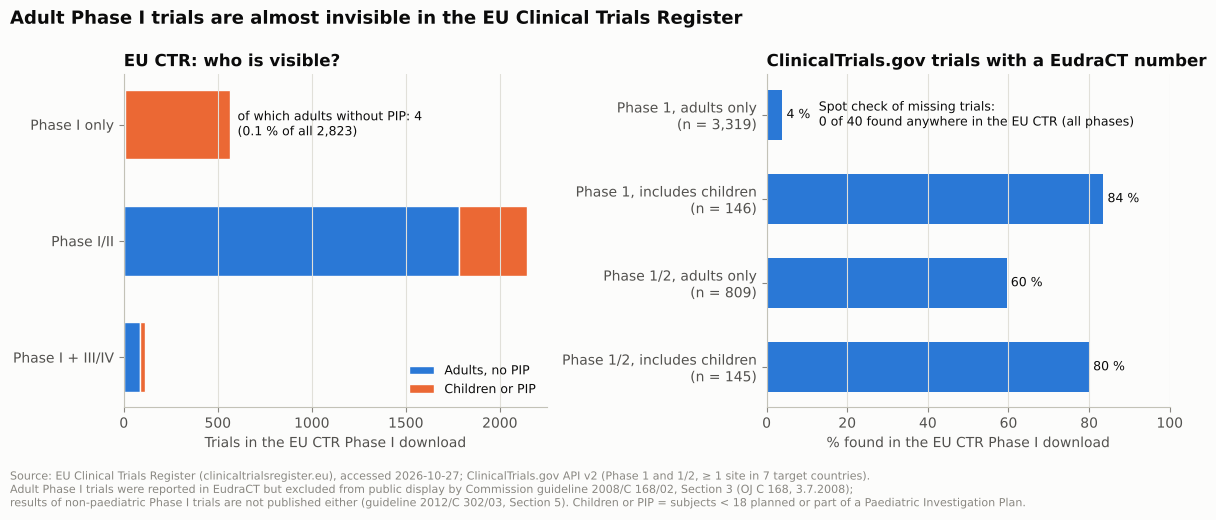

In [12]:
# Figure 12 – visibility: EU CTR study mix (left) and CT.gov trials found in the EU CTR (right)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.05, 1]})
y = np.arange(len(PHASES))[::-1]
left = np.zeros(len(PHASES))
for i, pop in enumerate(POPS):
    vals = mix.loc[pop, PHASES].to_numpy(dtype=float)
    ax1.barh(y, vals, left=left, color=vs.SERIES[i], label=pop, height=0.6, edgecolor=vs.SURFACE, linewidth=1)
    left += vals
ax1.set_yticks(y, PHASES)
ax1.grid(axis="y", visible=False)
ax1.grid(axis="x", visible=True)
ax1.set_xlabel("Trials in the EU CTR Phase I download")
ax1.set_title("EU CTR: who is visible?")
n_adult_p1 = int(mix.loc["Adults, no PIP", "Phase I only"])
ax1.text(mix.loc["Total", "Phase I only"] + 40, y[0],
         f"of which adults without PIP: {n_adult_p1}\n({100 * n_adult_p1 / len(euctr):.1f} % of all {len(euctr):,})",
         va="center", fontsize=9, color=vs.INK_PRIMARY)
ax1.legend(loc="lower right", fontsize=9)

lab = [f"{r['ClinicalTrials.gov phase']}, {r['population'].lower()}\n(n = {r['trials with EudraCT no.']:,})"
       for _, r in vis.iterrows()]
share = 100 * vis["found in EU CTR Phase I download"] / vis["trials with EudraCT no."]
y2 = np.arange(len(vis))[::-1]
ax2.barh(y2, share, color=vs.SERIES[0], height=0.6)
for yy, s in zip(y2, share):
    ax2.text(s + 1, yy, f"{s:.0f} %", va="center", fontsize=9, color=vs.INK_PRIMARY)
ax2.set_yticks(y2, lab)
ax2.set_xlim(0, 100)
ax2.grid(axis="y", visible=False)
ax2.grid(axis="x", visible=True)
ax2.set_xlabel("% found in the EU CTR Phase I download")
ax2.set_title("ClinicalTrials.gov trials with a EudraCT number")
n_spot_found = int((spot["EU CTR protocols (all phases)"] > 0).sum())
ax2.text(share.iloc[0] + 9, y2[0],
         f"Spot check of missing trials:\n{n_spot_found} of {len(spot)} found anywhere in the EU CTR (all phases)",
         va="center", fontsize=9, color=vs.INK_PRIMARY)
fig.suptitle("Adult Phase I trials are almost invisible in the EU Clinical Trials Register",
             x=0.01, ha="left", fontsize=13, fontweight="bold", y=0.99)
fig.tight_layout()
vs.source_note(fig, EU_SOURCE + "; ClinicalTrials.gov API v2 (Phase 1 and 1/2, ≥ 1 site in 7 target countries).\n"
               "Adult Phase I trials were reported in EudraCT but excluded from public display by Commission guideline 2008/C 168/02, "
               "Section 3 (OJ C 168, 3.7.2008);\nresults of non-paediatric Phase I trials are not published either "
               "(guideline 2012/C 302/03, Section 5). "
               "Children or PIP = subjects < 18 planned or part of a Paediatric Investigation Plan.", y=-0.01)
vs.save(fig, FIGURES / "12_eudract_visibility_gap.png")
plt.show()

Saved figure: 13_eudract_definitions.png


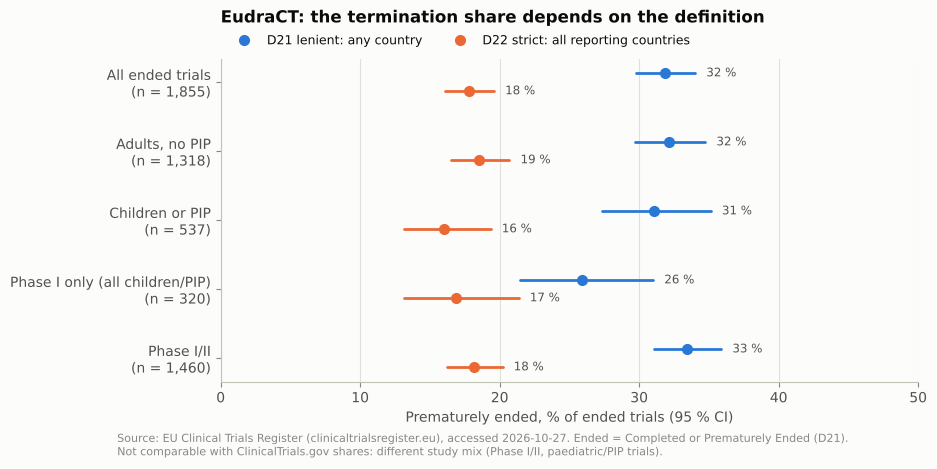

In [13]:
# Figure 13 – D21 vs. D22 by stratum (dot plot with Wilson CIs)
groups = [("All ended trials", ended)] + [(p, ended[ended["population"] == p]) for p in POPS] \
         + [("Phase I only (all children/PIP)", ended[ended["phase_combo"] == "Phase I only"]),
            ("Phase I/II", ended[ended["phase_combo"] == "Phase I/II"])]
fig, ax = plt.subplots(figsize=(9, 4.2))
yy = np.arange(len(groups))[::-1]
for j, (col, name) in enumerate([("pe_D21", "D21 lenient: any country"), ("pe_D22", "D22 strict: all reporting countries")]):
    for y0, (g, d) in zip(yy, groups):
        k, n = int(d[col].sum()), len(d)
        lo, hi = proportion_confint(k, n, method="wilson")
        off = 0.13 if j == 0 else -0.13
        ax.plot([100 * lo, 100 * hi], [y0 + off] * 2, color=vs.SERIES[j], lw=2, solid_capstyle="round")
        ax.plot(100 * k / n, y0 + off, "o", color=vs.SERIES[j], ms=7, label=name if y0 == yy[0] else None)
        ax.text(100 * hi + 0.8, y0 + off, f"{100 * k / n:.0f} %", va="center", fontsize=8.5, color=vs.INK_SECONDARY)
ax.set_yticks(yy, [f"{g}\n(n = {len(d):,})" for g, d in groups])
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlim(0, 50)
ax.set_xlabel("Prematurely ended, % of ended trials (95 % CI)")
ax.set_title("EudraCT: the termination share depends on the definition", pad=26)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, fontsize=9)
vs.source_note(fig, EU_SOURCE + ". Ended = Completed or Prematurely Ended (D21).\n"
               "Not comparable with ClinicalTrials.gov shares: different study mix (Phase I/II, paediatric/PIP trials).",
               y=-0.01)
vs.save(fig, FIGURES / "13_eudract_definitions.png")
plt.show()

## Summary Part A (Block 18)

1. **The EU CTR Phase I download is not a sample of Phase I trials.** Of 2,823 trials, 76 % are
   Phase I/II, 34 % involve children or a PIP; only **4 (0.1 %)** are adult, non-PIP, Phase-I-only
   trials (none of them first-in-human).
2. **Visibility gap (numbers):** 3,319 adult Phase 1 trials registered on ClinicalTrials.gov with a
   EudraCT number → only 131 (3.9 %) appear in the EU CTR Phase I download, and **all** of these are
   classified there as Phase I/II, Phase I + III/IV or PIP – none as adult Phase-I-only. A random
   sample of 40 missing trials was not found in the EU CTR at all (0/40, all phases). For comparison:
   60–84 % of Phase 1/2 or paediatric trials are found. In CTIS, 376 of 399 transitioned adult
   non-PIP Phase I trials (94 %) became public for the first time.
3. **Definition matters:** prematurely ended **31.9 % (D21, lenient)** vs. **17.8 % (D22, strict)**
   of 1,855 ended trials. Single-country trials: 23.7 % under both; the whole difference comes from
   multi-country trials (43.5 % vs. 9.4 %).
4. **No termination reason** in the EU CTR protocol data (section P has only status and end date)
   → no safety analysis possible for EudraCT.
5. **Results:** 58.8 % of all Phase I trials in the download have results in the EU CTR – but this
   includes ongoing trials. Where posting was **due** (ended, global end ≥ 12 months before the
   download; obligation: 12 months, paediatric 6 months, guideline 2012/C 302/03): **80.0 %**
   (Completed 81 %, Prematurely Ended 77 %). Only availability at the download date is measured,
   not whether results were posted on time; 342 ended trials without a global end date are excluded.
6. **Not directly comparable with ClinicalTrials.gov:** Phase I/II 79 % vs. 22 %, children 28 % vs.
   6 %, healthy volunteers 12 % vs. 47 %. Stratum-wise comparison → Block 20.

---
# Part B – CTIS and cross-registry matching (Block 19)

**CTIS** (Clinical Trials Information System) is the EU database under the Clinical Trials Regulation
(EU) No 536/2014 (CTR): used since 31 January 2022, mandatory for new applications since
31 January 2023, and for all trials still running on 30 January 2025 (transition from the Directive).
CTIS data are **young** (decisions 2022–2026) → descriptive only (D14).

## B1 – Publication rules in CTIS (what is public, and when)

| Period | Rule | Phase I (Category 1) |
|---|---|---|
| 31 Jan 2022 – 17 Jun 2024 | *Appendix, on disclosure rules, to the functional specifications for the EU portal and EU database* (EMA, 2015) | Trials are grouped in categories; **Category 1** = Phase I (healthy volunteers or patients), Phase 0, bioequivalence/bioavailability, biosimilarity. A **deferral mechanism** allowed sponsors to delay publication of certain data and documents, *"including the protocol, for up to 7-years from the end of the trial"* (EMA/263067/2023, Section 2). Integrated **Phase I/II = Category 2**. |
| from 18 Jun 2024 | **Revised CTIS Transparency Rules** (EMA/263067/2023, adopted 5 Oct 2023) | **No deferrals** for any category. *Category 1, adults only:* selected structured data (lay title, identifiers, condition, age/gender, sponsor, sites) at the first decision; **remaining structured data, protocol/synopsis and summary of results 30 months after the end of the trial in the EU/EEA**. *Category 1, paediatric and/or PIP:* structured data at decision, protocol together with the results. For **all** categories, notifications on start, end of trial **including early termination** and temporary halt are published *"as soon as the notification is submitted by the sponsor"*. |
| Trials submitted before 18 Jun 2024 ("historical trials") | EMA quick guide *Revised CTIS transparency rules and historical trials* | Only **structured data** are published; documents are *"not published (this applies to all historical trials, regardless of the previous use of deferrals or publication status)"*. |

Legal basis: Article 81(4) CTR (public EU database; exceptions for personal data, commercially
confidential information, communication between Member States, supervision) and Article 81(5) (no
publication before the decision).

**Consequences for this project**
- Unlike the EU CTR, adult Phase I trials **are** visible in CTIS from the first decision – but with a
  reduced data set until 30 months after their end.
- **Early termination is published immediately** (date + coded reason per member state) for all
  categories → termination analysis is possible in CTIS, results/protocol analyses for adult Phase I
  are not yet.
- Most trials in our download were submitted before 18 June 2024 → documents are not public for them.

Sources: [Revised CTIS Transparency Rules, EMA/263067/2023](https://www.ema.europa.eu/en/documents/other/revised-ctis-transparency-rules_en.pdf);
[EMA news, 6 Oct 2023](https://www.ema.europa.eu/en/news/revised-transparency-rules-eu-clinical-trials-information-system-ctis);
[Revised CTIS transparency rules and historical trials – quick guide for users (ACT EU)](https://accelerating-clinical-trials.europa.eu/document/download/a101771b-0be7-492f-b8bd-7f551ffbb7a7_en);
Regulation (EU) No 536/2014, Article 81.

In [14]:
import gzip
import hashlib

CTIS_RAW = PROJECT_DIR / "data" / "raw" / "ctis"
cmeta = json.loads((CTIS_RAW / "ctis_metadata.json").read_text())
CTIS_DATE = cmeta["downloaded_at_utc"][:10]
CTIS_SOURCE = f"Source: CTIS public portal (euclinicaltrials.eu), European Medicines Agency, accessed {CTIS_DATE}"

# Re-read the raw full records once: NCT number field and coded early-termination reason per member state
parsed = []
with gzip.open(CTIS_RAW / "ctis_phase1_details_raw.jsonl.gz", "rt", encoding="utf-8") as f:
    for line in f:
        r = json.loads(line)
        part1 = (r.get("authorizedApplication") or {}).get("authorizedPartI") or {}
        ident = ((part1.get("trialDetails") or {}).get("clinicalTrialIdentifiers") or {})
        sec = ident.get("secondaryIdentifyingNumbers") or {}
        nct_raw = str((sec.get("nctNumber") or {}).get("number") or "")
        m = re.search(r"NCT(?!0{8})\d{8}", nct_raw.upper().replace(" ", ""))   # NCT00000000 = placeholder
        events = (r.get("events") or {}).get("trialEvents") or []
        et = [(ev.get("mscName"), (ev.get("earlyTerminationReason") or {}).get("name"))
              for ev in events
              if any(e.get("notificationType") == "EARLY_TERMINATION" for e in ev.get("events", []))]
        parsed.append({"ct_number": r.get("ctNumber"), "nct_ctis": m.group(0) if m else None,
                       "nct_field_filled": bool(nct_raw.strip()), "et_events": et})
parsed = pd.DataFrame(parsed)

ctis = ctis.merge(parsed, on="ct_number", how="left", validate="1:1")
ctis["group"] = np.where(ctis["healthy_volunteers"], "Healthy volunteers", "Patients only")
ctis["industry"] = ctis["sponsor_type"].fillna("").str.contains("Pharmaceutical company|Industry|SME")
ctis["origin"] = np.where(ctis["is_transitioned"], "Transitioned from EudraCT", "New under the CTR")
ctis["decision_year"] = ctis["decision_date"].str[:4].astype(int)
print(f"CTIS Phase I download ({CTIS_DATE}): {len(ctis):,} trials; NCT field filled: "
      f"{int(ctis['nct_field_filled'].sum()):,}, valid NCT number: {int(ctis['nct_ctis'].notna().sum()):,} "
      f"(the rest: placeholders such as NCT00000000 or no NCT format)")

overview = pd.concat({
    "Phase": ctis["phase_group"].value_counts(),
    "Status": ctis["status_group"].value_counts(),
    "Origin": ctis["origin"].value_counts(),
    "Population": ctis["group"].value_counts(),
    "Sponsor": ctis["industry"].map({True: "Industry", False: "Non-industry"}).value_counts(),
    "Decision year": ctis["decision_year"].value_counts().sort_index(),
}).rename("trials").to_frame()
overview["%"] = (100 * overview["trials"] / len(ctis)).round(1)
display(overview)
print("Healthy volunteers incl. 167 trials with healthy volunteers AND patients.")

CTIS Phase I download (2026-10-28): 3,522 trials; NCT field filled: 1,107, valid NCT number: 1,105 (the rest: placeholders such as NCT00000000 or no NCT format)


trials     %
Phase         Phase I                      2354  66.8
              Phase I/II                   1168  33.2
Status        ended                        1603  45.5
              ongoing                      1552  44.1
              not_started                   367  10.4
Origin        New under the CTR            2570  73.0
              Transitioned from EudraCT     952  27.0
Population    Patients only                2312  65.6
              Healthy volunteers           1210  34.4
Sponsor       Industry                     2804  79.6
              Non-industry                  718  20.4
Decision year 2022                           52   1.5
              2023                          528  15.0
              2024                         1595  45.3
              2025                          721  20.5
              2026                          626  17.8

Healthy volunteers incl. 167 trials with healthy volunteers AND patients.


## B2 – Early termination in CTIS: lenient vs. strict (analogous to D21/D22)

CTIS records end of trial per member state; an early termination is the notification type
`EARLY_TERMINATION`. **Lenient:** early termination in ≥ 1 member state; **strict:** in all member
states with an end notification (D24). Denominator: trials with overall status *Ended*.

In [15]:
ended_c = ctis[ctis["status_group"] == "ended"].copy()


def et_row(label, d):
    k1, k2, n = int(d["early_termination_any"].sum()), int(d["early_termination_all"].sum()), len(d)
    return {"group": label, "ended trials": n, "lenient: n": k1, "lenient % (95 % CI)": wilson(k1, n),
            "strict: n": k2, "strict % (95 % CI)": wilson(k2, n)}


rows = [et_row("All ended trials", ended_c)]
for col in ["origin", "phase_group", "group"]:
    for v in sorted(ended_c[col].unique()):
        rows.append(et_row(f"  {v}", ended_c[ended_c[col] == v]))
ctis_et = pd.DataFrame(rows)
ctis_et.to_csv(PROCESSED / "table_ctis_early_termination.csv", index=False)
display(ctis_et)

,group,ended trials,lenient: n,lenient % (95 % CI),strict: n,strict % (95 % CI)
0,All ended trials,1603,441,27.5 (25.4–29.7),360,22.5 (20.5–24.6)
1,New under the CTR,1180,260,22.0 (19.8–24.5),219,18.6 (16.4–20.9)
2,Transitioned from EudraCT,423,181,42.8 (38.2–47.5),141,33.3 (29.0–38.0)
3,Phase I,1285,277,21.6 (19.4–23.9),241,18.8 (16.7–21.0)
4,Phase I/II,318,164,51.6 (46.1–57.0),119,37.4 (32.3–42.9)
5,Healthy volunteers,884,73,8.3 (6.6–10.3),71,8.0 (6.4–10.0)
6,Patients only,719,368,51.2 (47.5–54.8),289,40.2 (36.7–43.8)


## B3 – Healthy volunteers vs. patients (D25) – only together with right-censoring

**Why the share among *ended* trials is misleading here.** CTIS contains trials decided 2022–2026.
Healthy-volunteer Phase I trials are short (weeks to months) – most of them have already ended,
normally or early. Patient trials (often oncology, dose escalation + expansion) run for years: of
those that have *already* ended, many ended **because** they were stopped early, while the ones that
will complete regularly are mostly **still running**. The share "early terminated among ended" is
therefore biased upwards for patient trials (right-censoring). In addition, **transitioned** trials
are a selected group: only trials still running on 30 January 2025 were transitioned, i.e. long
trials.

The table shows the D25 figure **next to** three less biased views: the status distribution (how
many trials have ended at all), early terminations among **all** trials (a lower bound, because
running trials may still stop), and the oldest cohort of new CTR trials (decision 2022–2023, ≥ 2.8
years of follow-up).

In [16]:
def d25_row(label, d):
    n = len(d)
    e = d[d["status_group"] == "ended"]
    k_e, k_all = int(e["early_termination_any"].sum()), int(d["early_termination_any"].sum())
    return {"group": label, "trials": n,
            "% ended": round(100 * len(e) / n, 1),
            "% still ongoing": round(100 * (d["status_group"] == "ongoing").mean(), 1),
            "% not started": round(100 * (d["status_group"] == "not_started").mean(), 1),
            "early terminated among ENDED (D25), % (95 % CI)": wilson(k_e, len(e)),
            "early terminated among ALL trials, % (95 % CI)": wilson(k_all, n)}


cohort = ctis[(ctis["origin"] == "New under the CTR") & (ctis["decision_year"] <= 2023)]
rows = []
for scope, d0 in [("All CTIS Phase I", ctis), ("New CTR trials, decision 2022–2023", cohort),
                  ("Transitioned trials (selected: running on 30 Jan 2025)", ctis[ctis["is_transitioned"]])]:
    for g in ["Healthy volunteers", "Patients only"]:
        rows.append(d25_row(f"{scope} – {g}", d0[d0["group"] == g]))
d25 = pd.DataFrame(rows)
d25.to_csv(PROCESSED / "table_ctis_hv_vs_patients_censoring.csv", index=False)
display(d25)

,group,trials,% ended,% still ongoing,% not started,"early terminated among ENDED (D25), % (95 % CI)","early terminated among ALL trials, % (95 % CI)"
0,All CTIS Phase I – Healthy volunteers,1210,73.1,19.5,7.4,8.3 (6.6–10.3),6.2 (5.0–7.7)
1,All CTIS Phase I – Patients only,2312,31.1,56.9,12.0,51.2 (47.5–54.8),19.9 (18.4–21.6)
2,"New CTR trials, decision 2022–2023 – Healthy v...",257,91.4,4.7,3.9,7.2 (4.6–11.3),7.0 (4.5–10.8)
3,"New CTR trials, decision 2022–2023 – Patients ...",234,47.0,45.3,7.7,60.0 (50.7–68.7),34.2 (28.4–40.5)
4,Transitioned trials (selected: running on 30 J...,63,47.6,46.0,6.3,30.0 (16.7–47.9),15.9 (8.9–26.8)
5,Transitioned trials (selected: running on 30 J...,889,44.2,53.1,2.7,43.8 (38.9–48.7),23.2 (20.5–26.1)


Saved figure: 14_ctis_hv_vs_patients_censoring.png


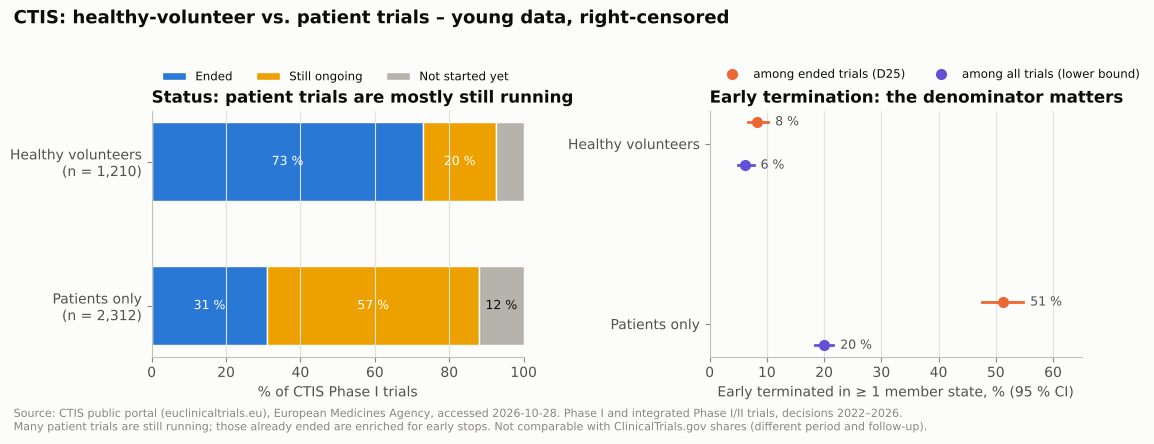

In [17]:
# Figure 14 – status distribution and early-termination share under two denominators
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={"width_ratios": [1, 1]})
groups = ["Healthy volunteers", "Patients only"]
yy = np.arange(len(groups))[::-1]
left = np.zeros(len(groups))
status_cols = [("ended", "Ended", vs.SERIES[0]), ("ongoing", "Still ongoing", vs.SERIES[3]),
               ("not_started", "Not started yet", vs.NEUTRAL)]
for key, lab, colr in status_cols:
    vals = np.array([100 * (ctis.loc[ctis["group"] == g, "status_group"] == key).mean() for g in groups])
    ax1.barh(yy, vals, left=left, color=colr, label=lab, height=0.55, edgecolor=vs.SURFACE, linewidth=1)
    for y0, l0, v in zip(yy, left, vals):
        if v >= 8:
            ax1.text(l0 + v / 2, y0, f"{v:.0f} %", ha="center", va="center", fontsize=9,
                     color="white" if key != "not_started" else vs.INK_PRIMARY)
    left += vals
ax1.set_yticks(yy, [f"{g}\n(n = {int((ctis['group'] == g).sum()):,})" for g in groups])
ax1.set_xlim(0, 100)
ax1.grid(axis="y", visible=False)
ax1.grid(axis="x", visible=True)
ax1.set_xlabel("% of CTIS Phase I trials")
ax1.set_title("Status: patient trials are mostly still running")
ax1.legend(loc="lower left", bbox_to_anchor=(0, 1.07), ncol=3, fontsize=8.5)

for j, (den, lab) in enumerate([("ended", "among ended trials (D25)"), ("all", "among all trials (lower bound)")]):
    for y0, g in zip(yy, groups):
        d = ctis[ctis["group"] == g]
        if den == "ended":
            d = d[d["status_group"] == "ended"]
        k, n = int(d["early_termination_any"].sum()), len(d)
        lo, hi = proportion_confint(k, n, method="wilson")
        off = 0.12 if j == 0 else -0.12
        ax2.plot([100 * lo, 100 * hi], [y0 + off] * 2, color=vs.SERIES[1 + j * 5], lw=2)
        ax2.plot(100 * k / n, y0 + off, "o", color=vs.SERIES[1 + j * 5], ms=7, label=lab if g == groups[0] else None)
        ax2.text(100 * hi + 1.2, y0 + off, f"{100 * k / n:.0f} %", va="center", fontsize=9, color=vs.INK_SECONDARY)
ax2.set_yticks(yy, groups)
ax2.set_xlim(0, 65)
ax2.grid(axis="y", visible=False)
ax2.grid(axis="x", visible=True)
ax2.set_xlabel("Early terminated in ≥ 1 member state, % (95 % CI)")
ax2.set_title("Early termination: the denominator matters")
ax2.legend(loc="lower left", bbox_to_anchor=(0, 1.08), ncol=2, fontsize=8.5)
fig.suptitle("CTIS: healthy-volunteer vs. patient trials – young data, right-censored",
             x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.0)
fig.subplots_adjust(top=0.74, wspace=0.5)
vs.source_note(fig, CTIS_SOURCE + ". Phase I and integrated Phase I/II trials, decisions 2022–2026.\n"
               "Many patient trials are still running; those already ended are enriched for early stops. "
               "Not comparable with ClinicalTrials.gov shares (different period and follow-up).", y=-0.02)
vs.save(fig, FIGURES / "14_ctis_hv_vs_patients_censoring.png")
plt.show()

## B4 – Coded termination reason in CTIS vs. ClinicalTrials.gov

CTIS publishes **one coded reason per member state** (9 codes) and **no free text**.
ClinicalTrials.gov has a free-text field (`why_stopped`), classified in notebook 03 (rules v2 +
expert review). To compare both, the categories are harmonised:

| Harmonised | CTIS code | ClinicalTrials.gov (notebook 03) |
|---|---|---|
| Safety | Safety Related (Clinical or Pre-Clinical Results) | Safety |
| Efficacy/Futility | – (no code) | Efficacy/Futility |
| Recruitment/feasibility | Feasibility (recruitment issues, etc) | Recruitment |
| Strategic/business/funding | Reprioritisation of Trial, Merger, Divestment | Strategic/Business, Funding |
| Other | Study Related, Investigator / Site related, Medicinal Product Related | Other, COVID-19 |
| **No specific reason** | **Sponsor Decision** | **Sponsor decision (unspecified), Not stated** |

Trial level (CTIS): a trial gets the **most specific** code reported by any member state (priority
Safety > Recruitment/feasibility > Strategic/business/funding > Other > No specific reason) –
"Sponsor Decision" therefore counts as *no specific reason* only if **no** member state gave a more
specific code. Denominator: ended trials with early termination in ≥ 1 member state.

In [18]:
CTIS_MAP = {"Sponsor Decision": "No specific reason",
            "Safety Related (Clinical or Pre-Clinical Results)": "Safety",
            "Feasibility (recruitment issues, etc)": "Recruitment/feasibility",
            "Reprioritisation of Trial": "Strategic/business/funding", "Merger": "Strategic/business/funding",
            "Divestment": "Strategic/business/funding",
            "Study Related": "Other", "Investigator / Site related": "Other", "Medicinal Product Related": "Other"}
CTG_MAP = {"Safety": "Safety", "Efficacy/Futility": "Efficacy/Futility", "Recruitment": "Recruitment/feasibility",
           "Strategic/Business": "Strategic/business/funding", "Funding": "Strategic/business/funding",
           "Other": "Other", "COVID-19": "Other",
           "Sponsor decision (unspecified)": "No specific reason", "Not stated": "No specific reason"}
HARM = ["Safety", "Efficacy/Futility", "Recruitment/feasibility", "Strategic/business/funding", "Other",
        "No specific reason"]
assert set(CTIS_MAP) >= {r for ev in ctis["et_events"] for _, r in ev if r}, "unknown CTIS code"

# country level
ev = ctis[["ct_number", "et_events"]].explode("et_events").dropna()
ev["reason"] = ev["et_events"].str[1]
print(f"Member-state early-termination notifications: {len(ev):,} in {ev['ct_number'].nunique():,} trials")
display(ev["reason"].value_counts().rename("notifications").to_frame()
        .assign(**{"%": lambda d: (100 * d["notifications"] / d["notifications"].sum()).round(1)}))

# trial level (ended + early terminated)
et_c = ended_c[ended_c["early_termination_any"]].copy()
et_c["codes"] = et_c["ct_number"].map(ev.groupby("ct_number")["reason"].agg(set))
et_c["harm_codes"] = et_c["codes"].map(lambda c: {CTIS_MAP[x] for x in c})
et_c["primary_h"] = et_c["harm_codes"].map(lambda c: next(h for h in HARM if h in c))
n_et = len(et_c)
any_sponsor = int(et_c["codes"].map(lambda c: "Sponsor Decision" in c).sum())
only_sponsor = int(et_c["codes"].map(lambda c: c == {"Sponsor Decision"}).sum())
print(f"Ended + early terminated: {n_et}; 'Sponsor Decision' in >= 1 member state: {any_sponsor} "
      f"({100 * any_sponsor / n_et:.1f} %); 'Sponsor Decision' as the ONLY code: {only_sponsor} "
      f"({100 * only_sponsor / n_et:.1f} %)")

all_et = ctis[ctis["early_termination_any"]]
k_all_sp = int(all_et["et_events"].map(lambda e: any(r == "Sponsor Decision" for _, r in e)).sum())
print(f"Check of denominators: 'Sponsor Decision' in {k_all_sp} of {len(all_et)} trials with early termination in "
      f">= 1 MS (any status) = {100 * k_all_sp / len(all_et):.1f} %; {k_all_sp}/{n_et} would mix two denominators.")

ws = pd.read_parquet(PROCESSED / "why_stopped_final.parquet")
ws["primary_h"] = ws["primary_reason_final"].map(CTG_MAP)
cmp_rows = []
for h in HARM:
    k_any = int(et_c["harm_codes"].map(lambda c: h in c).sum())
    k_pri = int((et_c["primary_h"] == h).sum())
    k_ctg = int((ws["primary_h"] == h).sum())
    cmp_rows.append({"harmonised reason": h,
                     "CTIS: in >= 1 member state, % (95 % CI)": wilson(k_any, n_et),
                     "CTIS: trial-level (most specific), % (95 % CI)": wilson(k_pri, n_et),
                     "ClinicalTrials.gov: primary reason, % (95 % CI)": wilson(k_ctg, len(ws))})
reason_cmp = pd.DataFrame(cmp_rows)
reason_cmp.to_csv(PROCESSED / "table_reasons_ctis_vs_ctgov.csv", index=False)
print(f"CTIS n = {n_et} ended trials with early termination (decisions 2022–2026); "
      f"ClinicalTrials.gov n = {len(ws):,} terminated trials (start 2005–2022)")
display(reason_cmp)
for c in ["Sponsor decision (unspecified)", "Not stated"]:
    k = int((ws["primary_reason_final"] == c).sum())
    print(f"ClinicalTrials.gov '{c}': {k} = {wilson(k, len(ws))}")

Member-state early-termination notifications: 1,049 in 536 trials


,notifications,%
reason,,
Sponsor Decision,860,82.0
"Feasibility (recruitment issues, etc)",72,6.9
Safety Related (Clinical or Pre-Clinical Results),45,4.3
Reprioritisation of Trial,28,2.7
Study Related,24,2.3
Investigator / Site related,13,1.2
Medicinal Product Related,4,0.4
Merger,2,0.2
Divestment,1,0.1


Ended + early terminated: 441; 'Sponsor Decision' in >= 1 member state: 355 (80.5 %); 'Sponsor Decision' as the ONLY code: 350 (79.4 %)
Check of denominators: 'Sponsor Decision' in 429 of 536 trials with early termination in >= 1 MS (any status) = 80.0 %; 429/441 would mix two denominators.
CTIS n = 441 ended trials with early termination (decisions 2022–2026); ClinicalTrials.gov n = 1,154 terminated trials (start 2005–2022)


,harmonised reason,"CTIS: in >= 1 member state, % (95 % CI)","CTIS: trial-level (most specific), % (95 % CI)","ClinicalTrials.gov: primary reason, % (95 % CI)"
0,Safety,3.9 (2.4–6.1),3.9 (2.4–6.1),9.4 (7.9–11.3)
1,Efficacy/Futility,0.0 (0.0–0.9),0.0 (0.0–0.9),10.1 (8.4–11.9)
2,Recruitment/feasibility,9.5 (7.1–12.6),9.1 (6.7–12.1),13.2 (11.3–15.2)
3,Strategic/business/funding,2.3 (1.2–4.1),2.3 (1.2–4.1),27.5 (25.0–30.1)
4,Other,5.4 (3.7–8.0),5.4 (3.7–8.0),19.0 (16.8–21.3)
5,No specific reason,80.5 (76.5–83.9),79.4 (75.3–82.9),20.9 (18.6–23.3)


ClinicalTrials.gov 'Sponsor decision (unspecified)': 98 = 8.5 (7.0–10.2)
ClinicalTrials.gov 'Not stated': 143 = 12.4 (10.6–14.4)


## B5 – ID matching: which CTIS Phase I trials are also on ClinicalTrials.gov?

Links are taken from **both** sides:
1. **CTIS → ClinicalTrials.gov:** field *NCT number* in the CTIS record (secondary identifiers).
2. **ClinicalTrials.gov → CTIS:** EU CT numbers (`YYYY-5NNNNN-NN`) or, for transitioned trials, the
   EudraCT number listed as secondary ID in the ClinicalTrials.gov download (Phase 1 / 1/2 trials with
   a site in the 7 target countries – links from trials outside these countries are missed).

All linked NCT numbers are then retrieved from the ClinicalTrials.gov API v2 (batches of 100, cached)
to get their current status and `why_stopped` text.

In [19]:
ctg_all = pd.read_parquet(INTERIM / "ctgov_flat.parquet")
sec = (ctg_all[["nct_id", "eudract_ids"]].dropna()
       .assign(sid=lambda d: d["eudract_ids"].str.split(r"[;,|]\s*")).explode("sid"))
sec["sid"] = sec["sid"].str.strip()
ctis["ct14"] = ctis["ct_number"].str[:14]
dup_eudract = ctis[ctis["is_transitioned"]]["eudract_number"].duplicated(keep=False)
print(f"Transitioned CTIS records sharing a EudraCT number with another record: {int(dup_eudract.sum())}")
l1 = (sec[sec["sid"].str.match(r"^\d{4}-5\d{5}-\d{2}")].assign(ct14=lambda d: d["sid"].str[:14])
      .merge(ctis[["ct14", "ct_number"]], on="ct14"))
l2 = sec.merge(ctis.loc[ctis["is_transitioned"], ["eudract_number", "ct_number"]],
               left_on="sid", right_on="eudract_number")
links_ctg = pd.concat([l1, l2])[["ct_number", "nct_id"]].drop_duplicates()
links_ctis = ctis.dropna(subset=["nct_ctis"])[["ct_number", "nct_ctis"]].rename(columns={"nct_ctis": "nct_id"})
links = (links_ctis.assign(from_ctis=True).merge(links_ctg.assign(from_ctgov=True),
                                                  on=["ct_number", "nct_id"], how="outer"))
links[["from_ctis", "from_ctgov"]] = links[["from_ctis", "from_ctgov"]].fillna(False).astype(bool)

per_trial = links.groupby("ct_number").agg(n_nct=("nct_id", "nunique"), from_ctis=("from_ctis", "any"),
                                           from_ctgov=("from_ctgov", "any"))
ctis["has_nct"] = ctis["ct_number"].isin(per_trial.index)
ctis["link_source"] = ctis["ct_number"].map(
    per_trial.apply(lambda r: "both sides" if r["from_ctis"] and r["from_ctgov"]
                    else ("CTIS field only" if r["from_ctis"] else "ClinicalTrials.gov only"), axis=1)
).fillna("no link")
conflicts = per_trial[per_trial["n_nct"] > 1]
print(f"CTIS Phase I trials with >= 1 NCT link: {int(ctis['has_nct'].sum()):,} of {len(ctis):,} "
      f"({100 * ctis['has_nct'].mean():.1f} %); trials with > 1 different NCT number: {len(conflicts)}")
display(ctis["link_source"].value_counts().rename("trials").to_frame())

rows = []
for col, lab in [("phase_group", "Phase"), ("origin", "Origin"), ("group", "Population"),
                 ("industry", "Industry sponsor"), ("status_group", "CTIS status")]:
    for v in sorted(ctis[col].unique(), key=str):
        d = ctis[ctis[col] == v]
        k = int(d["has_nct"].sum())
        rows.append({"characteristic": lab, "value": v, "trials": len(d), "with NCT": k,
                     "% (95 % CI)": wilson(k, len(d))})
nct_tab = pd.DataFrame(rows)
nct_tab.to_csv(PROCESSED / "table_ctis_nct_linkage.csv", index=False)
display(nct_tab)

Transitioned CTIS records sharing a EudraCT number with another record: 7
CTIS Phase I trials with >= 1 NCT link: 1,844 of 3,522 (52.4 %); trials with > 1 different NCT number: 9


,trials
link_source,
no link,1678
ClinicalTrials.gov only,739
both sides,561
CTIS field only,544


,characteristic,value,trials,with NCT,% (95 % CI)
0,Phase,Phase I,2354,1035,44.0 (42.0–46.0)
1,Phase,Phase I/II,1168,809,69.3 (66.6–71.8)
2,Origin,New under the CTR,2570,1126,43.8 (41.9–45.7)
3,Origin,Transitioned from EudraCT,952,718,75.4 (72.6–78.0)
4,Population,Healthy volunteers,1210,287,23.7 (21.4–26.2)
5,Population,Patients only,2312,1557,67.3 (65.4–69.2)
6,Industry sponsor,False,718,299,41.6 (38.1–45.3)
7,Industry sponsor,True,2804,1545,55.1 (53.3–56.9)
8,CTIS status,ended,1603,718,44.8 (42.4–47.2)
9,CTIS status,not_started,367,101,27.5 (23.2–32.3)


In [20]:
# Current ClinicalTrials.gov record for every linked NCT number (cached batches)
LINK_DIR = PROJECT_DIR / "data" / "raw" / "ctgov_ctis_links"
LINK_DIR.mkdir(exist_ok=True)
ncts = sorted(links["nct_id"].unique())
recs = []
for i in range(0, len(ncts), 100):
    batch = ncts[i:i + 100]
    key = hashlib.md5(",".join(batch).encode()).hexdigest()[:10]
    url = ("https://clinicaltrials.gov/api/v2/studies?filter.ids=" + ",".join(batch)
           + "&fields=NCTId|OverallStatus|WhyStopped|Phase|StartDate|LastUpdatePostDate&pageSize=100")
    js = json.loads(get_cached(url, LINK_DIR / f"batch_{i // 100:03d}_{key}.json", pause=1.0))
    for st in js.get("studies", []):
        sm = st["protocolSection"]["statusModule"]
        recs.append({"nct_id": st["protocolSection"]["identificationModule"]["nctId"],
                     "ctgov_status": sm.get("overallStatus"), "why_stopped": sm.get("whyStopped"),
                     "ctgov_update": (sm.get("lastUpdatePostDateStruct") or {}).get("date")})
ctg_now = pd.DataFrame(recs).drop_duplicates("nct_id")
LINK_DATE = pd.Timestamp.fromtimestamp(min(f.stat().st_mtime for f in LINK_DIR.glob("batch_*.json"))).date()
print(f"Linked NCT numbers: {len(ncts):,}; found in ClinicalTrials.gov API: {len(ctg_now):,} (retrieved {LINK_DATE})")
not_found = sorted(set(ncts) - set(ctg_now["nct_id"]))
print("Not found (invalid or withdrawn numbers):", not_found[:10], "…" if len(not_found) > 10 else "")

Linked NCT numbers: 1,832; found in ClinicalTrials.gov API: 1,829 (retrieved 2026-11-09)
Not found (invalid or withdrawn numbers): ['NCT00161943', 'NCT04392504', 'NCT04693598', 'NCT20170516'] 


**Status agreement for linked trials.** One CTIS trial is compared with its (first) linked
ClinicalTrials.gov record. CTIS *ended with early termination in ≥ 1 member state* is compared with
ClinicalTrials.gov *Terminated*. Differences are expected: CTIS status is EU-specific, the
ClinicalTrials.gov status is global, and both registries are updated at different times.

In [21]:
pair = (links.drop_duplicates("ct_number")[["ct_number", "nct_id"]]
        .merge(ctg_now, on="nct_id", how="inner")
        .merge(ctis[["ct_number", "status_group", "early_termination_any", "early_termination_all", "group",
                     "phase_group"]], on="ct_number"))
pair["CTIS"] = np.select([pair["status_group"].eq("ended") & pair["early_termination_any"],
                          pair["status_group"].eq("ended"), pair["early_termination_any"]],
                         ["Ended – early termination", "Ended – completed", "Ongoing – early termination in some MS"],
                         default="Ongoing / not started")
CTG_GROUP = {"TERMINATED": "Terminated", "COMPLETED": "Completed", "ACTIVE_NOT_RECRUITING": "Active",
             "RECRUITING": "Active", "ENROLLING_BY_INVITATION": "Active", "NOT_YET_RECRUITING": "Active",
             "WITHDRAWN": "Withdrawn", "SUSPENDED": "Suspended", "UNKNOWN": "Unknown"}
pair["ClinicalTrials.gov"] = pair["ctgov_status"].map(CTG_GROUP).fillna(pair["ctgov_status"])
status_x = pd.crosstab(pair["CTIS"], pair["ClinicalTrials.gov"], margins=True)
status_x.to_csv(PROCESSED / "table_ctis_ctgov_status_agreement.csv")
display(status_x)
both_et = pair[pair["CTIS"].eq("Ended – early termination")]
k = int((both_et["ClinicalTrials.gov"] == "Terminated").sum())
print(f"CTIS ended with early termination -> ClinicalTrials.gov 'Terminated': {k} of {len(both_et)} ({wilson(k, len(both_et))})")

# Is the gap only a matter of definition? Strict = early termination in ALL member states with an end notification
rows = []
for lab, d in [("Early termination in >= 1 MS (lenient)", both_et),
               ("  … in ALL MS (strict)", both_et[both_et["early_termination_all"]]),
               ("  … in some MS only, completed in others (mixed)", both_et[~both_et["early_termination_all"]])]:
    vc = d["ClinicalTrials.gov"].value_counts()
    k = int(vc.get("Terminated", 0))
    rows.append({"CTIS: ended, …": lab, "trials": len(d), "CT.gov Terminated": k,
                 "% Terminated (95 % CI)": wilson(k, len(d)), "CT.gov Completed": int(vc.get("Completed", 0)),
                 "CT.gov Active": int(vc.get("Active", 0)),
                 "other (unknown, withdrawn, suspended)": len(d) - k - int(vc.get("Completed", 0)) - int(vc.get("Active", 0))})
strict_x = pd.DataFrame(rows)
strict_x.to_csv(PROCESSED / "table_ctis_ctgov_status_agreement_strict.csv", index=False)
display(strict_x)
st = both_et[both_et["early_termination_all"] & both_et["ClinicalTrials.gov"].isin(["Active", "Completed"])]
upd = pd.to_datetime(st["ctgov_update"], errors="coerce")
print(f"Strict, but Active/Completed on ClinicalTrials.gov (n = {len(st)}): last ClinicalTrials.gov update median "
      f"{upd.median():%Y-%m}, {int((upd < pd.Timestamp(LINK_DATE) - pd.DateOffset(months=12)).sum())} not updated "
      f"for > 12 months")

ClinicalTrials.gov,Active,Completed,Suspended,Terminated,Unknown,Withdrawn,All
CTIS,,,,,,,
Ended – completed,54,337,1,24,9,0,425
Ended – early termination,58,58,0,165,5,6,292
Ongoing / not started,990,12,3,3,34,0,1042
Ongoing – early termination in some MS,81,0,1,0,0,0,82
All,1183,407,5,192,48,6,1841


CTIS ended with early termination -> ClinicalTrials.gov 'Terminated': 165 of 292 (56.5 (50.8–62.1))


,"CTIS: ended, …",trials,CT.gov Terminated,% Terminated (95 % CI),CT.gov Completed,CT.gov Active,"other (unknown, withdrawn, suspended)"
0,Early termination in >= 1 MS (lenient),292,165,56.5 (50.8–62.1),58,58,11
1,… in ALL MS (strict),224,139,62.1 (55.5–68.2),35,40,10
2,"… in some MS only, completed in others (mixed)",68,26,38.2 (27.6–50.1),23,18,1


Strict, but Active/Completed on ClinicalTrials.gov (n = 75): last ClinicalTrials.gov update median 2026-03, 21 not updated for > 12 months


**Same trial, two registries: what does "Sponsor Decision" hide?** For trials that are early
terminated in CTIS **and** *Terminated* on ClinicalTrials.gov, the ClinicalTrials.gov `why_stopped`
text is classified with the same rules as in notebook 03 (rules v2, module `why_stopped_rules.py`,
verified to reproduce the stored v2 labels). These texts were **not** expert-reviewed.

In [22]:
import why_stopped_rules as wsr

check = ws["why_stopped"].map(lambda t: wsr.primary_reason(wsr.classify(t)[0]))
assert (check == ws["primary_reason_v2"]).all(), "module does not reproduce notebook 03"

same = both_et[both_et["ClinicalTrials.gov"] == "Terminated"].merge(
    et_c[["ct_number", "primary_h", "codes"]], on="ct_number")
same["ctgov_reason"] = same["why_stopped"].map(lambda t: wsr.primary_reason(wsr.classify(t)[0]))
same["ctgov_h"] = same["ctgov_reason"].map(CTG_MAP)
same_x = pd.crosstab(same["primary_h"], same["ctgov_h"], margins=True).reindex(
    index=[h for h in HARM if h in same["primary_h"].unique()] + ["All"],
    columns=[h for h in HARM if h in same["ctgov_h"].unique()] + ["All"])
same_x.index.name, same_x.columns.name = "CTIS (trial level)", "ClinicalTrials.gov why_stopped (rules v2)"
same_x.to_csv(PROCESSED / "table_reasons_same_trials.csv")
print(f"Trials early terminated in CTIS and 'Terminated' on ClinicalTrials.gov: {len(same)}")
display(same_x)
sp = same[same["primary_h"] == "No specific reason"]
print(f"\nCTIS 'Sponsor Decision' only (n = {len(sp)}) – reason given on ClinicalTrials.gov:")
display(sp["ctgov_reason"].value_counts().rename("trials").to_frame())
display(sp[["ct_number", "nct_id", "why_stopped"]].head(12))

Trials early terminated in CTIS and 'Terminated' on ClinicalTrials.gov: 165


ClinicalTrials.gov why_stopped (rules v2),Safety,Efficacy/Futility,Recruitment/feasibility,Strategic/business/funding,Other,No specific reason,All
CTIS (trial level),,,,,,,
Safety,3,2,0,1,0,5,11
Recruitment/feasibility,1,0,7,0,2,1,11
Strategic/business/funding,1,0,0,1,0,1,3
Other,2,0,0,0,4,1,7
No specific reason,7,9,4,70,11,32,133
All,14,11,11,72,17,40,165



CTIS 'Sponsor Decision' only (n = 133) – reason given on ClinicalTrials.gov:


,trials
ctgov_reason,
Strategic/Business,68
Sponsor decision (unspecified),26
Other,11
Efficacy/Futility,9
Safety,7
Not stated,6
Recruitment,4
Funding,2


,ct_number,nct_id,why_stopped
0,2022-500094-14-00,NCT05229900,Study closed due to portfolio prioritization
1,2022-500391-62-00,NCT05403450,ASTX660-03 was closed according to protocol as...
2,2022-500614-26-00,NCT06000891,Decision by Sponsor; LSLV was completed on 21-...
3,2022-500868-36-00,NCT04465487,Sponsor Decision
4,2022-501363-40-00,NCT05480865,Business Reasons
5,2022-501474-19-00,NCT04892017,"Trial terminated due to business decision, not..."
6,2022-501985-23-00,NCT05534529,The study had initially anticipated dosing of ...
7,2022-502057-33-00,NCT05839626,Early discontinuation based on sponsor decisio...
8,2022-502087-21-00,NCT05160168,The Sponsor terminated the study due to early ...
9,2022-502125-17-00,NCT05839600,NaN


Saved figure: 15_termination_reasons_ctis_vs_ctgov.png


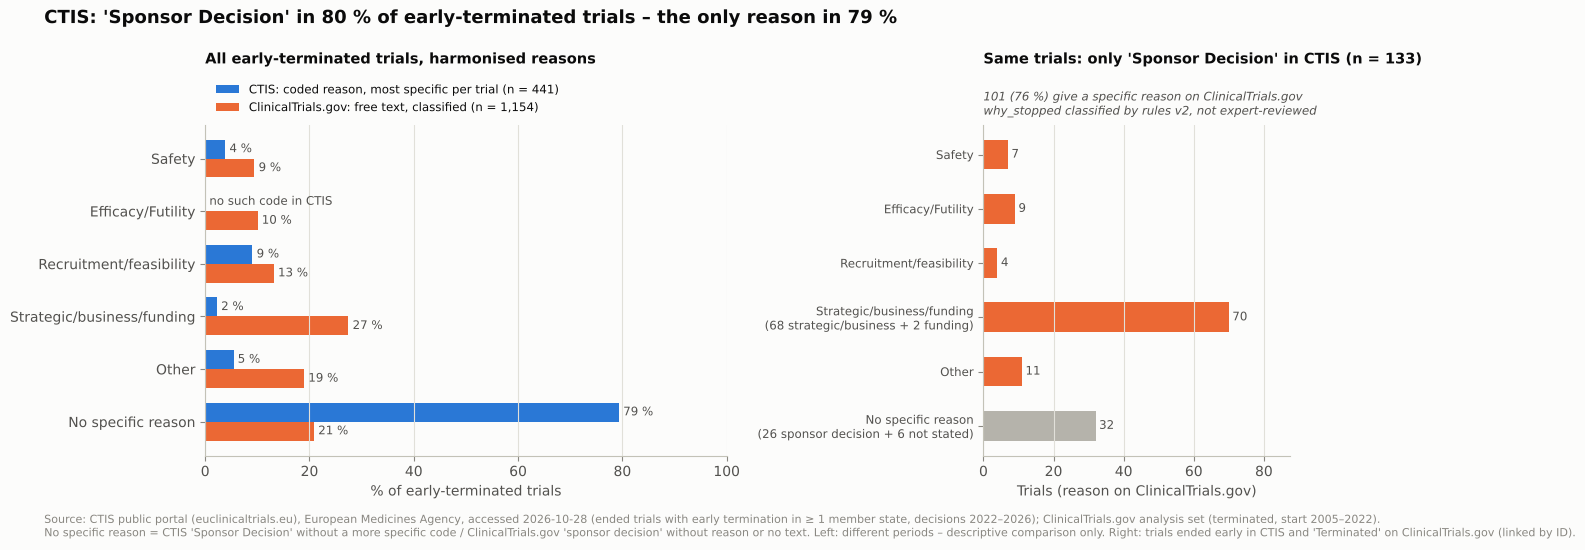

In [23]:
# Figure 15 – harmonised termination reasons: CTIS (trial level) vs. ClinicalTrials.gov + same-trial panel
fig, (ax, axr) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.7, 1]})
yy = np.arange(len(HARM))[::-1]
h = 0.36
for j, (lab, ser, n, colr) in enumerate([
        (f"CTIS: coded reason, most specific per trial (n = {n_et})", et_c["primary_h"], n_et, vs.SERIES[0]),
        (f"ClinicalTrials.gov: free text, classified (n = {len(ws):,})", ws["primary_h"], len(ws), vs.SERIES[1])]):
    vals = np.array([100 * (ser == c).sum() / n for c in HARM])
    off = h / 2 if j == 0 else -h / 2
    ax.barh(yy + off, vals, height=h, color=colr, label=lab)
    for y0, v, c in zip(yy, vals, HARM):
        txt = "no such code in CTIS" if (j == 0 and c == "Efficacy/Futility") else f"{v:.0f} %"
        ax.text(v + 0.8, y0 + off, txt, va="center", fontsize=8.5, color=vs.INK_SECONDARY)
ax.set_yticks(yy, HARM)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlim(0, 100)
ax.set_xlabel("% of early-terminated trials")
fig.suptitle(f"CTIS: 'Sponsor Decision' in {100 * any_sponsor / n_et:.0f} % of early-terminated trials – "
             f"the only reason in {100 * only_sponsor / n_et:.0f} %", x=0.01, ha="left", fontsize=13,
             fontweight="bold", y=1.04)
ax.set_title("All early-terminated trials, harmonised reasons", pad=44, fontsize=10.5)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=1, fontsize=8.5)

# right panel: the same trials – only "Sponsor Decision" in CTIS, reason on ClinicalTrials.gov
vals_r = np.array([(sp["ctgov_h"] == c).sum() for c in HARM])
n_spec = int((sp["ctgov_h"] != "No specific reason").sum())
axr.barh(yy, vals_r, height=0.55, color=[vs.NEUTRAL if c == "No specific reason" else vs.SERIES[1] for c in HARM])
for y0, v in zip(yy, vals_r):
    axr.text(v + 1, y0, f"{v}", va="center", fontsize=8.5, color=vs.INK_SECONDARY)
rc = sp["ctgov_reason"].value_counts()
lab_r = []
for cat in HARM:
    parts = [f"{int(rc[r])} {r.split(' (')[0].lower()}" for r, h in CTG_MAP.items() if h == cat and r in rc]
    lab_r.append(cat if len(parts) <= 1 else f"{cat}\n({' + '.join(parts)})")
axr.set_yticks(yy, lab_r, fontsize=8.5)
axr.grid(axis="y", visible=False)
axr.grid(axis="x", visible=True)
axr.set_xlim(0, max(vals_r) * 1.25)
axr.set_xlabel("Trials (reason on ClinicalTrials.gov)")
axr.set_title(f"Same trials: only 'Sponsor Decision' in CTIS (n = {len(sp)})", pad=44, fontsize=10.5)
axr.text(0, 1.03, f"{n_spec} ({100 * n_spec / len(sp):.0f} %) give a specific reason on ClinicalTrials.gov\n"
         "why_stopped classified by rules v2, not expert-reviewed", transform=axr.transAxes,
         fontsize=8.5, color=vs.INK_SECONDARY, style="italic")
fig.subplots_adjust(wspace=0.62, top=0.8)
vs.source_note(fig, CTIS_SOURCE + " (ended trials with early termination in ≥ 1 member state, decisions 2022–2026); "
               "ClinicalTrials.gov analysis set (terminated, start 2005–2022).\n"
               "No specific reason = CTIS 'Sponsor Decision' without a more specific code / ClinicalTrials.gov "
               "'sponsor decision' without reason or no text. Left: different periods – descriptive comparison only. "
               "Right: trials ended early in CTIS and 'Terminated' on ClinicalTrials.gov (linked by ID).",
               y=-0.01)
vs.save(fig, FIGURES / "15_termination_reasons_ctis_vs_ctgov.png")
plt.show()

## Summary Part B (Block 19)

1. **Publication rules.** CTIS shows adult Phase I trials (unlike the EU CTR) and publishes early
   terminations immediately. For adult Category 1 trials, most details, the protocol and the results
   follow only **30 months after the end of the trial** (revised rules, from 18 June 2024; before:
   deferrals of up to 7 years). Documents of trials submitted before 18 June 2024 are not published.
2. **Early termination** (ended trials, n = 1,603): 27.5 % lenient vs. 22.5 % strict; transitioned
   42.8 % vs. new 22.0 % (selected group).
3. **D25 – only with right-censoring:** among *ended* trials 8.3 % (healthy volunteers) vs. 51.2 %
   (patients); but only 31 % of patient trials have ended (73 % of HV trials). Among *all* trials
   (lower bound) 6.2 % vs. 19.9 %; oldest new-CTR cohort (decision 2022–2023) 7.0 % vs. 34.2 %.
   A difference remains in every view, but its size depends strongly on the denominator.
4. **Coded reason:** "Sponsor Decision" in 80.5 % of ended, early-terminated trials and the **only**
   code in 79.4 % – vs. 20.9 % without a specific reason on ClinicalTrials.gov (sponsor decision
   unspecified 8.5 % + not stated 12.4 %). CTIS has no code for efficacy/futility; safety 3.9 % vs. 9.4 %.
   For the same trials (n = 133 with only "Sponsor Decision" in CTIS and *Terminated* on
   ClinicalTrials.gov), ClinicalTrials.gov names a specific reason in 101 (76 %), incl. 7 safety and
   9 efficacy/futility (rules v2, not expert-reviewed).
5. **ID linkage:** 1,844 of 3,522 CTIS Phase I trials (52.4 %) are linked to an NCT number (CTIS field
   only 544, ClinicalTrials.gov side only 739, both 561); healthy-volunteer trials only 23.7 %,
   patient trials 67.3 %. Of 292 linked trials ended early in CTIS (≥ 1 member state), 165 (56.5 %) are
   *Terminated* on ClinicalTrials.gov; with the strict definition (early termination in **all**
   member states, n = 224) 139 (62.1 %), with mixed EU statuses (n = 68) only 26 (38.2 %). The
   definition explains part of the gap, but even under the strict definition 35 trials are
   *Completed* and 40 *Active* on ClinicalTrials.gov (global vs. EU status; 21 of these 75 records not
   updated for > 12 months).

---
# Part C – Comparing the three registries (Block 20)

Two questions:
1. **Termination shares within the same strata.** The overall shares are not comparable because the
   study mix differs (Part A7). Here they are compared only **within** the same phase and population.
2. **Transparency.** What does each registry show about Phase I trials, their termination and the
   reason for it?

**Common strata** (built from each registry's own fields):

| Stratum | Phase | Age | Population |
|---|---|---|---|
| S1 | Phase I only | adults only | healthy volunteers accepted |
| S2 | Phase I only | adults only | patients only |
| S3 | Phase I/II | adults only | patients only |
| S4 | Phase I only | includes children | any |
| S5 | Phase I/II | includes children | any |

| Registry | Phase I only / Phase I/II | Children | Healthy volunteers | Termination (denominator: ended trials) |
|---|---|---|---|---|
| ClinicalTrials.gov | `PHASE1` / `PHASE1\|PHASE2` | eligible age includes < 18 | "accepts healthy volunteers" | *Terminated* among Completed + Terminated (analysis set, start 2005–2022) |
| EU CTR | Phase I flag without / with Phase II flag (I + III/IV excluded) | subjects < 18 planned | healthy volunteers planned | D21 lenient / D22 strict, among Completed + Prematurely Ended |
| CTIS | "Phase I" / "Phase I and Phase II (Integrated)" | age group 0–17 | healthy volunteers | lenient / strict, among *Ended* (decisions 2022–2026, **right-censored**) |

**Remaining differences that strata cannot remove:** period (ClinicalTrials.gov 2005–2022,
EU CTR entries 2004–2023, CTIS 2022–2026), status definition (one global status vs. per member
state), and right-censoring in CTIS. The comparison is descriptive.

In [24]:
STRATA = ["S1 Phase I only · adults · healthy volunteers", "S2 Phase I only · adults · patients only",
          "S3 Phase I/II · adults · patients only", "S4 Phase I only · incl. children",
          "S5 Phase I/II · incl. children"]


def stratum(phase_1_2, children, hv):
    """Common stratum label from three booleans (None = not one of S1–S5)."""
    if children:
        return STRATA[4] if phase_1_2 else STRATA[3]
    if not phase_1_2:
        return STRATA[0] if hv else STRATA[1]
    return None if hv else STRATA[2]


ana = pd.read_parquet(PROCESSED / "ctgov_analysis_dataset.parquet")
ana["stratum"] = [stratum(bool(p), bool(c), bool(h)) for p, c, h in
                  zip(ana["phase_1_2"], ana["includes_children"], ana["healthy_volunteers"])]
ana["term_lenient"] = ana["terminated"].astype(bool)
ana["term_strict"] = ana["term_lenient"]                      # one global status: no strict variant

eu_s = ended[ended["phase_combo"] != "Phase I + III/IV"].copy()
eu_s["stratum"] = [stratum(p == "Phase I/II", bool(c), bool(h)) for p, c, h in
                   zip(eu_s["phase_combo"], eu_s["subjects_under_18"], eu_s["healthy_volunteers"])]
eu_s["term_lenient"], eu_s["term_strict"] = eu_s["pe_D21"], eu_s["pe_D22"]

ct_s = ended_c.copy()
ct_s["children"] = ct_s["age_group"].fillna("").str.contains("0-17")
ct_s["stratum"] = [stratum(p == "Phase I/II", bool(c), bool(h)) for p, c, h in
                   zip(ct_s["phase_group"], ct_s["children"], ct_s["healthy_volunteers"])]
ct_s["term_lenient"], ct_s["term_strict"] = ct_s["early_termination_any"], ct_s["early_termination_all"]

REG = {"ClinicalTrials.gov": ana, "EU CTR (EudraCT)": eu_s, "CTIS": ct_s}
rows = []
for st in ["All ended trials"] + STRATA:
    for reg, d0 in REG.items():
        d = d0 if st == "All ended trials" else d0[d0["stratum"] == st]
        n = len(d)
        k1, k2 = int(d["term_lenient"].sum()), int(d["term_strict"].sum())
        rows.append({"stratum": st, "registry": reg, "ended trials": n,
                     "lenient: n": k1, "lenient % (95 % CI)": wilson(k1, n) if n >= 20 else f"n = {n} – not shown",
                     "strict % (95 % CI)": ("= lenient (one status)" if reg == "ClinicalTrials.gov"
                                            else (wilson(k2, n) if n >= 20 else "–"))})
strata_tab = pd.DataFrame(rows)
strata_tab.to_csv(PROCESSED / "table_registry_comparison_strata.csv", index=False)
display(strata_tab)
print("Not in S1–S5: ClinicalTrials.gov", int(ana["stratum"].isna().sum()),
      "| EU CTR", int(eu_s["stratum"].isna().sum()), "| CTIS", int(ct_s["stratum"].isna().sum()),
      "(Phase I/II, adults, healthy volunteers accepted)")

,stratum,registry,ended trials,lenient: n,lenient % (95 % CI),strict % (95 % CI)
0,All ended trials,ClinicalTrials.gov,7960,1154,14.5 (13.7–15.3),= lenient (one status)
1,All ended trials,EU CTR (EudraCT),1780,571,32.1 (30.0–34.3),17.9 (16.2–19.8)
2,All ended trials,CTIS,1603,441,27.5 (25.4–29.7),22.5 (20.5–24.6)
3,S1 Phase I only · adults · healthy volunteers,ClinicalTrials.gov,3498,219,6.3 (5.5–7.1),= lenient (one status)
4,S1 Phase I only · adults · healthy volunteers,EU CTR (EudraCT),24,1,4.2 (0.7–20.2),4.2 (0.7–20.2)
5,S1 Phase I only · adults · healthy volunteers,CTIS,865,70,8.1 (6.5–10.1),7.9 (6.2–9.8)
6,S2 Phase I only · adults · patients only,ClinicalTrials.gov,2497,474,19.0 (17.5–20.6),= lenient (one status)
7,S2 Phase I only · adults · patients only,EU CTR (EudraCT),2,0,n = 2 – not shown,–
8,S2 Phase I only · adults · patients only,CTIS,396,197,49.7 (44.8–54.7),41.7 (36.9–46.6)
9,S3 Phase I/II · adults · patients only,ClinicalTrials.gov,1321,343,26.0 (23.7–28.4),= lenient (one status)


Not in S1–S5: ClinicalTrials.gov 173 | EU CTR 124 | CTIS 15 (Phase I/II, adults, healthy volunteers accepted)


## C2 – Same trials in EudraCT and ClinicalTrials.gov

Strata remove differences in study mix, but not in period or definition. A sharper test uses the
**same trials**: ClinicalTrials.gov records (Phase 1 or 1/2, site in the 7 target countries, any start
year) whose EudraCT number is in the EU CTR Phase I download, with an ended status in **both**
registries (EU CTR Completed / Prematurely Ended; ClinicalTrials.gov Completed / Terminated).

In [25]:
pair_eu = (ids.merge(ctg_all[["nct_id", "overall_status"]], on="nct_id")
           .merge(eu_s.reindex(columns=["eudract_number", "pe_D21", "pe_D22", "stratum", "n_reporting"])
                  .assign(in_eu=True).set_index("eudract_number"), left_on="eid", right_index=True))
pair_eu = pair_eu[pair_eu["overall_status"].isin(["COMPLETED", "TERMINATED"])].drop_duplicates("nct_id")
pair_eu["ct_term"] = pair_eu["overall_status"].eq("TERMINATED")
n_p = len(pair_eu)
rows = []
for lab, col in [("ClinicalTrials.gov: Terminated", "ct_term"), ("EU CTR D21 lenient: Prematurely Ended", "pe_D21"),
                 ("EU CTR D22 strict: Prematurely Ended", "pe_D22")]:
    k = int(pair_eu[col].sum())
    rows.append({"same trials (n = %d)" % n_p: lab, "n": k, "% (95 % CI)": wilson(k, n_p)})
same_eu = pd.DataFrame(rows)
display(same_eu)
agree = pd.crosstab(pair_eu["pe_D21"].map({True: "EU CTR: Prematurely Ended (D21)", False: "EU CTR: Completed"}),
                    pair_eu["ct_term"].map({True: "CT.gov: Terminated", False: "CT.gov: Completed"}), margins=True)
display(agree)
mixed = pair_eu[pair_eu["pe_D21"] & ~pair_eu["pe_D22"]]
print(f"Trials ended early in some EU countries only (D21 but not D22): {len(mixed)}; of these Terminated on "
      f"ClinicalTrials.gov: {int(mixed['ct_term'].sum())}")
from sklearn.metrics import cohen_kappa_score
for col in ["pe_D21", "pe_D22"]:
    agr = (pair_eu[col] == pair_eu["ct_term"]).mean()
    print(f"Agreement CT.gov Terminated vs. EU CTR {col}: {100 * agr:.1f} %, Cohen's kappa "
          f"{cohen_kappa_score(pair_eu[col], pair_eu['ct_term']):.2f}")
pd.concat([same_eu.assign(table="shares"), agree.reset_index().assign(table="crosstab")]).to_csv(
    PROCESSED / "table_same_trials_eudract_ctgov.csv", index=False)

,same trials (n = 542),n,% (95 % CI)
0,ClinicalTrials.gov: Terminated,166,30.6 (26.9–34.6)
1,EU CTR D21 lenient: Prematurely Ended,178,32.8 (29.0–36.9)
2,EU CTR D22 strict: Prematurely Ended,69,12.7 (10.2–15.8)


ct_term,CT.gov: Completed,CT.gov: Terminated,All
pe_D21,,,
EU CTR: Completed,307,57,364
EU CTR: Prematurely Ended (D21),69,109,178
All,376,166,542


Trials ended early in some EU countries only (D21 but not D22): 109; of these Terminated on ClinicalTrials.gov: 62
Agreement CT.gov Terminated vs. EU CTR pe_D21: 76.8 %, Cohen's kappa 0.46
Agreement CT.gov Terminated vs. EU CTR pe_D22: 74.0 %, Cohen's kappa 0.27


Saved figure: 16_registry_comparison_strata.png


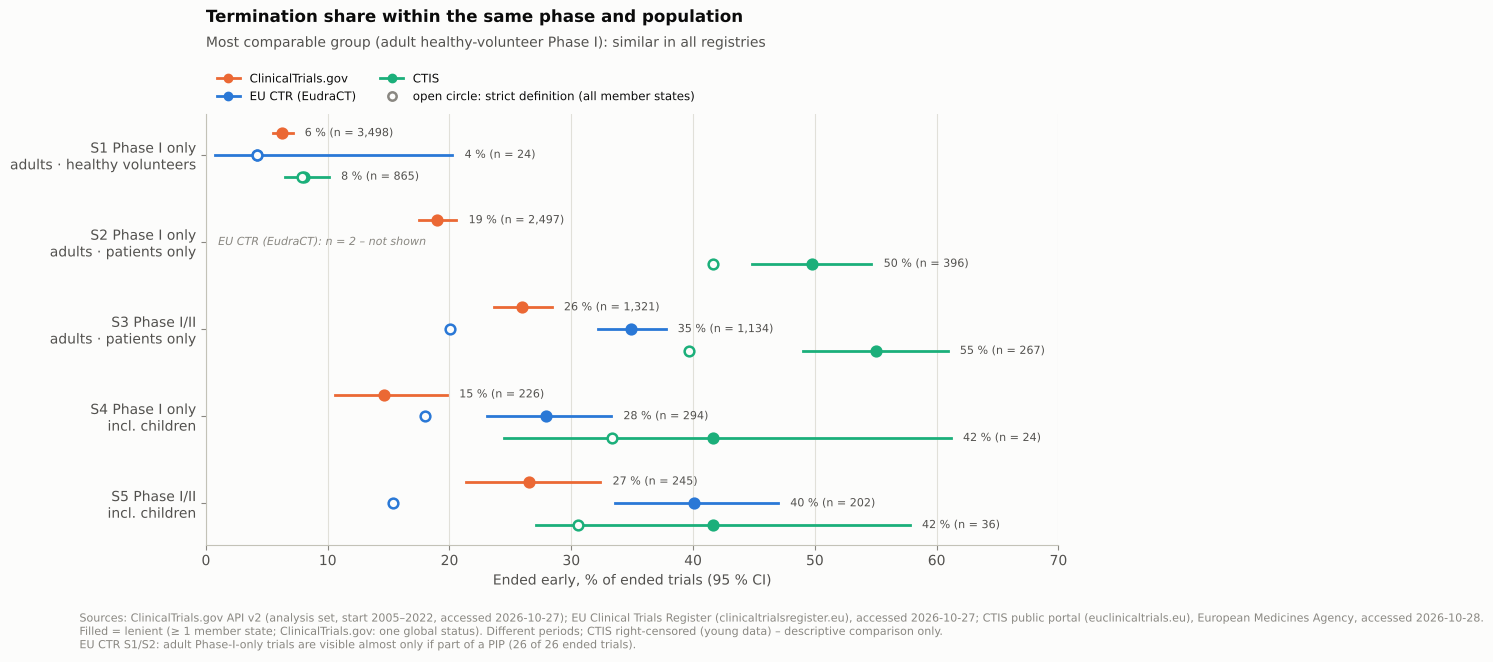

In [26]:
# Figure 16 – termination share within the same strata, three registries
show = STRATA
fig, ax = plt.subplots(figsize=(11, 5.6))
regs = list(REG)
cols = {"ClinicalTrials.gov": vs.SERIES[1], "EU CTR (EudraCT)": vs.SERIES[0], "CTIS": vs.SERIES[2]}
yy = np.arange(len(show))[::-1]
offs = {"ClinicalTrials.gov": 0.25, "EU CTR (EudraCT)": 0.0, "CTIS": -0.25}
for reg in regs:
    d0 = REG[reg]
    for y0, st in zip(yy, show):
        d = d0[d0["stratum"] == st]
        n = len(d)
        if n < 20:
            ax.text(1, y0 + offs[reg], f"{reg}: n = {n} – not shown", va="center", fontsize=8,
                    color=vs.INK_MUTED, style="italic")
            continue
        for col, filled in [("term_lenient", True), ("term_strict", False)]:
            if col == "term_strict" and reg == "ClinicalTrials.gov":
                continue
            k = int(d[col].sum())
            lo, hi = proportion_confint(k, n, method="wilson")
            if filled:
                ax.plot([100 * lo, 100 * hi], [y0 + offs[reg]] * 2, color=cols[reg], lw=2)
            ax.plot(100 * k / n, y0 + offs[reg], "o", ms=7, color=cols[reg],
                    mfc=cols[reg] if filled else vs.SURFACE, mew=1.8)
        k = int(d["term_lenient"].sum())
        ax.text(100 * proportion_confint(k, n, method="wilson")[1] + 1, y0 + offs[reg],
                f"{100 * k / n:.0f} % (n = {n:,})", va="center", fontsize=8, color=vs.INK_SECONDARY)
ax.set_yticks(yy, [s.replace(" · ", "\n", 1) for s in show])
ax.set_xlim(0, 70)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("Ended early, % of ended trials (95 % CI)")
handles = [plt.Line2D([], [], marker="o", color=cols[r], lw=2, label=r) for r in regs] + [
    plt.Line2D([], [], marker="o", color=vs.INK_MUTED, mfc=vs.SURFACE, lw=0, mew=1.8,
               label="open circle: strict definition (all member states)")]
ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, fontsize=8.5)
ax.set_title("Termination share within the same phase and population", pad=66)
ax.text(0, 1.155, "Most comparable group (adult healthy-volunteer Phase I): similar in all registries",
        transform=ax.transAxes, fontsize=10, color=vs.INK_SECONDARY)
vs.source_note(fig, "Sources: ClinicalTrials.gov API v2 (analysis set, start 2005–2022, accessed 2026-10-27); "
               + EU_SOURCE.replace("Source: ", "") + "; " + CTIS_SOURCE.replace("Source: ", "")
               + ".\nFilled = lenient (≥ 1 member state; ClinicalTrials.gov: one global status). Different periods; "
               "CTIS right-censored (young data) – descriptive comparison only.\n"
               f"EU CTR S1/S2: adult Phase-I-only trials are visible almost only if part of a PIP "
               f"({int(eu_s.loc[eu_s['stratum'].isin(STRATA[:2]), 'part_of_pip'].sum())} of "
               f"{int(eu_s['stratum'].isin(STRATA[:2]).sum())} ended trials).", y=-0.01)
vs.save(fig, FIGURES / "16_registry_comparison_strata.png")
plt.show()

## C3 – Transparency comparison

Each criterion is filled from the results of Parts A and B and notebook 03 (numbers computed
below where possible). Rating: **●** available · **◐** partly / with restrictions · **○** not available · **–** context only
(period, not rated).

In [27]:
eu_nct = set()
cur = None
for f in sorted(RAW_EU.glob("pages/page_*.txt")):
    for line in f.read_text(encoding="utf-8").splitlines():
        m = re.match(r"^EudraCT Number:\s*(\S+)", line)
        if m:
            cur = m.group(1)
        elif line.startswith("A.5.2") and re.search(r"NCT\d{8}", line):
            eu_nct.add(cur)
ct_eu_id = ctg_all["eudract_ids"].notna().mean()
res_ct = ana["has_results_posted"].mean()
res_ct_term = ana.loc[ana["terminated"] == 1, "has_results_posted"].mean()
k_due = res_tab.loc[res_tab["group"] == "Results due: all", ["with results", "trials"]].iloc[0]
ctis_res = ended_c["has_summary_results"].mean()
adult_cat1 = ended_c[(ended_c["phase_group"] == "Phase I") & ~ended_c["age_group"].fillna("").str.contains("0-17")
                     & ~ended_c["part_of_pip"]]
spec_ctg = 100 - 100 * (ws["primary_h"] == "No specific reason").mean()
win = pd.read_parquet(PROCESSED / "ctgov_window_dataset.parquet")
n_unknown = int((win["overall_status"] == "UNKNOWN").sum())
print(f"ClinicalTrials.gov trials started 2005–2022 with status UNKNOWN: {n_unknown} of {len(win):,}")

T = [
    ("Adult Phase I trials publicly visible",
     ("◐", "yes, if registered (Phase 1 exempt from FDAAA 801 registration duty)"),
     ("○", f"no – excluded by guideline 2008/C 168/02 (4 of {len(euctr):,} visible)"),
     ("◐", "yes, from decision; full data only 30 months after end of trial")),
    ("Termination status",
     ("●", f"one global status per trial; not always updated ({n_unknown} 'Unknown', start 2005–2022)"),
     ("◐", "per member state only; trial level must be derived (D21 31.9 % vs. D22 17.8 %)"),
     ("●", "per member state + overall status")),
    ("Reason for termination",
     ("●", f"free text (why_stopped); specific reason in {spec_ctg:.0f} % of terminated trials"),
     ("○", "none in protocol data"),
     ("◐", f"coded; 'Sponsor Decision' only code in {100 * only_sponsor / n_et:.0f} %, no efficacy code")),
    ("Results publicly available",
     ("◐", f"{100 * res_ct:.0f} % of analysis set (terminated {100 * res_ct_term:.0f} %); Phase 1 exempt from FDAAA results duty"),
     ("○", f"never for adult non-PIP Phase I (guideline 2012/C 302/03); the {100 * k_due['with results'] / k_due['trials']:.0f} % where due concern other (paediatric, PIP, Phase I/II) trials"),
     ("◐", f"{100 * ctis_res:.0f} % of ended trials; adult Category 1: published 30 months after end")),
    ("Machine-readable access",
     ("●", "documented REST API (v2)"),
     ("◐", "plain-text download, 20 trials per page"),
     ("◐", "public portal search interface (not a documented API)")),
    ("Link to the other registries",
     ("◐", f"{100 * ct_eu_id:.0f} % of Phase 1 and 1/2 trials with a site in the 7 countries list a EudraCT/EU CT number"),
     ("◐", f"{100 * len(eu_nct) / len(euctr):.0f} % list an NCT number (field A.5.2)"),
     ("◐", f"{100 * ctis['nct_ctis'].notna().mean():.0f} % list an NCT number; {100 * ctis['has_nct'].mean():.0f} % linked from either side")),
    ("Period covered in this project",
     ("–", "start 2005–2022 (analysis set)"),
     ("–", "entered 2004–2023; new applications until 30 Jan 2023"),
     ("–", "decisions 2022–2026; many trials still running")),
]
transp = pd.DataFrame([{"criterion": c, "ClinicalTrials.gov": f"{a[0]} {a[1]}", "EU CTR (EudraCT)": f"{b[0]} {b[1]}",
                        "CTIS": f"{d[0]} {d[1]}"} for c, a, b, d in T])
transp.to_csv(PROCESSED / "table_registry_transparency.csv", index=False)
with pd.option_context("display.max_colwidth", 90):
    display(transp)

ClinicalTrials.gov trials started 2005–2022 with status UNKNOWN: 469 of 9,076


,criterion,ClinicalTrials.gov,EU CTR (EudraCT),CTIS
0,Adult Phase I trials publicly visible,"◐ yes, if registered (Phase 1 exempt from FDAAA 801 registration duty)","○ no – excluded by guideline 2008/C 168/02 (4 of 2,823 visible)","◐ yes, from decision; full data only 30 months after end of trial"
1,Termination status,"● one global status per trial; not always updated (469 'Unknown', start 2005–2022)",◐ per member state only; trial level must be derived (D21 31.9 % vs. D22 17.8 %),● per member state + overall status
2,Reason for termination,● free text (why_stopped); specific reason in 79 % of terminated trials,○ none in protocol data,"◐ coded; 'Sponsor Decision' only code in 79 %, no efficacy code"
3,Results publicly available,◐ 23 % of analysis set (terminated 33 %); Phase 1 exempt from FDAAA results duty,○ never for adult non-PIP Phase I (guideline 2012/C 302/03); the 80 % where due concer...,◐ 20 % of ended trials; adult Category 1: published 30 months after end
4,Machine-readable access,● documented REST API (v2),"◐ plain-text download, 20 trials per page",◐ public portal search interface (not a documented API)
5,Link to the other registries,◐ 48 % of Phase 1 and 1/2 trials with a site in the 7 countries list a EudraCT/EU CT n...,◐ 22 % list an NCT number (field A.5.2),◐ 31 % list an NCT number; 52 % linked from either side
6,Period covered in this project,– start 2005–2022 (analysis set),– entered 2004–2023; new applications until 30 Jan 2023,– decisions 2022–2026; many trials still running


Saved figure: 17_registry_transparency_matrix.png


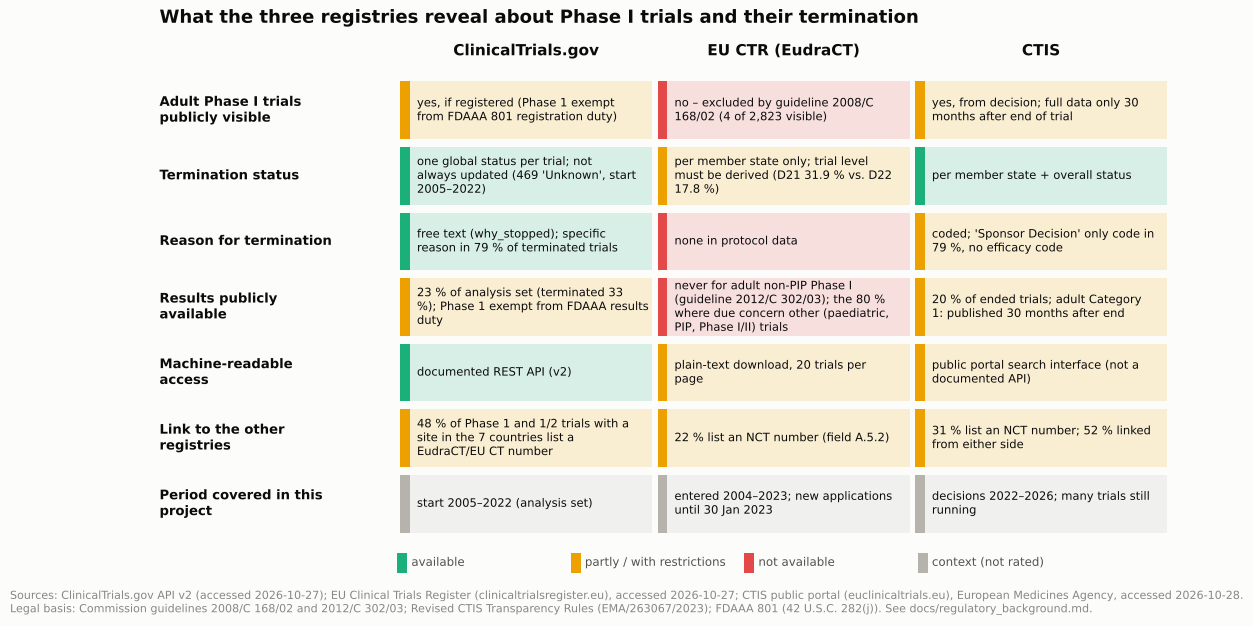

In [28]:
# Figure 17 – transparency matrix
import textwrap

RATE_COL = {"●": vs.SERIES[2], "◐": vs.SERIES[3], "○": vs.SERIES[7], "–": vs.NEUTRAL}
RATE_LAB = {"●": "available", "◐": "partly / with restrictions", "○": "not available", "–": "context (not rated)"}
fig, ax = plt.subplots(figsize=(13, 6.6))
ax.set_xlim(0, 3.6)
ax.set_ylim(len(T), -0.75)
ax.axis("off")
for j, reg in enumerate(["ClinicalTrials.gov", "EU CTR (EudraCT)", "CTIS"]):
    ax.text(0.85 + j * 0.92 + 0.46, -0.4, reg, ha="center", va="center", fontsize=11, fontweight="bold",
            color=vs.INK_PRIMARY)
for i, (crit, *cells) in enumerate(T):
    ax.text(0.0, i + 0.5, textwrap.fill(crit, 22), va="center", fontsize=9.5, fontweight="bold",
            color=vs.INK_PRIMARY)
    for j, (rate, txt) in enumerate(cells):
        x0 = 0.85 + j * 0.92
        ax.add_patch(plt.Rectangle((x0 + 0.01, i + 0.06), 0.9, 0.88, color=RATE_COL[rate], alpha=0.16, lw=0))
        ax.add_patch(plt.Rectangle((x0 + 0.01, i + 0.06), 0.035, 0.88, color=RATE_COL[rate], lw=0))
        ax.text(x0 + 0.07, i + 0.5, textwrap.fill(txt, 38), va="center", fontsize=8.3, color=vs.INK_PRIMARY)
for k, (r, lab) in enumerate(RATE_LAB.items()):
    ax.add_patch(plt.Rectangle((0.85 + k * 0.62, len(T) + 0.25), 0.035, 0.3, color=RATE_COL[r], lw=0,
                               clip_on=False))
    ax.text(0.85 + k * 0.62 + 0.05, len(T) + 0.4, lab, va="center", fontsize=8.5, color=vs.INK_SECONDARY)
ax.set_title("What the three registries reveal about Phase I trials and their termination", loc="left",
             fontsize=13, pad=4)
vs.source_note(fig, "Sources: ClinicalTrials.gov API v2 (accessed 2026-10-27); "
               + EU_SOURCE.replace("Source: ", "") + "; " + CTIS_SOURCE.replace("Source: ", "")
               + ".\nLegal basis: Commission guidelines 2008/C 168/02 and 2012/C 302/03; Revised CTIS Transparency Rules "
               "(EMA/263067/2023); FDAAA 801 (42 U.S.C. 282(j)). See docs/regulatory_background.md.", y=0.03)
vs.save(fig, FIGURES / "17_registry_transparency_matrix.png")
plt.show()

## Summary Part C (Block 20)

1. **Within the same strata the gap between the registries shrinks.** Overall: ClinicalTrials.gov
   14.5 % vs. EU CTR 32.1 % (D21) / 17.9 % (D22). Phase I/II, adults, patients (S3): 26.0 % vs.
   34.9 % (D21) / 20.0 % (D22) – ClinicalTrials.gov lies **between** the two EudraCT definitions.
   Healthy volunteers (S1): low everywhere – ClinicalTrials.gov 6.3 %, CTIS 8.1 %, EU CTR 4.2 %
   (n = 24, all part of a PIP).
2. **Same trials (n = 542, ended in both):** ClinicalTrials.gov *Terminated* 30.6 % vs. EU CTR D21
   32.8 % / D22 12.7 %. The higher overall EudraCT share is therefore mainly a matter of **study mix**,
   not of a different termination frequency. Agreement per trial is only moderate (D21: 76.8 %,
   kappa 0.46; D22: kappa 0.27).
3. **CTIS** shares are higher in all patient strata (S2 49.7 %, S3 55.1 %), consistent with
   right-censoring of young data (Part B) – not a sign of more terminations under the CTR.
4. **Transparency (figure 17):** ClinicalTrials.gov is the only registry with an informative
   termination reason and a documented API, but Phase 1 trials are not subject to the FDAAA
   registration and results duty. The EU CTR hides adult Phase I trials and has no reason; CTIS shows
   them, but with a mostly uninformative coded reason and a 30-month delay for details and results.